<a href="https://colab.research.google.com/github/Andrian0s/ML4NLP1-2026-Tutorial-Notebooks/blob/main/exercises/ex2/ex2_word_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML4NLP1
## Starting Point for Exercise 2

This notebook is supposed to serve as a starting point and/or inspiration when starting exercise 2. It begins with the PyTorch tutorial on word embeddings; the exercise itself starts at *Exercise: Computing Word Embeddings: Continuous Bag-of-Words*.

Throughout the notebook, there are questions that you should address in your report. These are marked with 📝❓ and are collected again in the lab report section at the end of the notebook.

## Use of generative AI

AI tools may be used in this exercise to help you explain code, debug, improve documentation, and explore alternatives. Any use must be documented in the *Declaration on the use of AI* at the end of this notebook (which tools were used and for which purposes). You remain responsible for understanding, checking, and testing everything you submit, and you must be able to explain any submitted text, code, analyses, and AI-assisted contributions. See the [CL guidelines on academic integrity and AI use](https://www.cl.uzh.ch/en/Studies/Services/academic-integrity.html).

# Setup

In [1]:
%pip install -q gensim==4.4.0 gdown

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Glyph .* missing from font')
warnings.filterwarnings('ignore', message='.*IProgress not found.*')
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import torch
# Pick the best available device: NVIDIA GPU, then Apple Silicon GPU, then CPU
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print(device)


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
mps


In [2]:
%matplotlib inline

In [3]:
# Mount Google Drive when running on Colab, so saved models survive a runtime restart.
# Outside Colab this cell does nothing, so the notebook also runs on JupyterHub or locally.
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Where trained models and vocabularies are saved
SAVE_DIR = '/content/drive/MyDrive/ml4nlp_ex2' if IN_COLAB else 'content/models'
os.makedirs(SAVE_DIR, exist_ok=True)
print(f"IN_COLAB = {IN_COLAB}, SAVE_DIR = {SAVE_DIR}")

IN_COLAB = False, SAVE_DIR = content/models


### Source (adapted): [link](https://pytorch.org/tutorials/beginner/nlp/word_embeddings_tutorial.html#exercise-computing-word-embeddings-continuous-bag-of-words)

# Word Embeddings: Encoding Lexical Semantics

Word embeddings are dense vectors of real numbers, one per word in your
vocabulary. In NLP, it is almost always the case that your features are
words! But how should you represent a word in a computer? You could
store its ascii character representation, but that only tells you what
the word *is*, it doesn't say much about what it *means* (you might be
able to derive its part of speech from its affixes, or properties from
its capitalization, but not much). Even more, in what sense could you
combine these representations? We often want dense outputs from our
neural networks, where the inputs are $|V|$ dimensional, where
$V$ is our vocabulary, but often the outputs are only a few
dimensional (if we are only predicting a handful of labels, for
instance). How do we get from a massive dimensional space to a smaller
dimensional space?

How about instead of ascii representations, we use a one-hot encoding?
That is, we represent the word $w$ by

\begin{align}\overbrace{\left[ 0, 0, \dots, 1, \dots, 0, 0 \right]}^\text{|V| elements}\end{align}

where the 1 is in a location unique to $w$. Any other word will
have a 1 in some other location, and a 0 everywhere else.

There is an enormous drawback to this representation, besides just how
huge it is. It basically treats all words as independent entities with
no relation to each other. What we really want is some notion of
*similarity* between words. Why? Let's see an example.

Suppose we are building a language model. Suppose we have seen the
sentences

* The mathematician ran to the store.
* The physicist ran to the store.
* The mathematician solved the open problem.

in our training data. Now suppose we get a new sentence never before
seen in our training data:

* The physicist solved the open problem.

Our language model might do OK on this sentence, but wouldn't it be much
better if we could use the following two facts:

* We have seen  mathematician and physicist in the same role in a sentence. Somehow they
  have a semantic relation.
* We have seen mathematician in the same role  in this new unseen sentence
  as we are now seeing physicist.

and then infer that physicist is actually a good fit in the new unseen
sentence? This is what we mean by a notion of similarity: we mean
*semantic similarity*, not simply having similar orthographic
representations. It is a technique to combat the sparsity of linguistic
data, by connecting the dots between what we have seen and what we
haven't. This example of course relies on a fundamental linguistic
assumption: that words appearing in similar contexts are related to each
other semantically. This is called the [distributional
hypothesis](https://en.wikipedia.org/wiki/Distributional_semantics).


# Getting Dense Word Embeddings

How can we solve this problem? That is, how could we actually encode
semantic similarity in words? Maybe we think up some semantic
attributes. For example, we see that both mathematicians and physicists
can run, so maybe we give these words a high score for the "is able to
run" semantic attribute. Think of some other attributes, and imagine
what you might score some common words on those attributes.

If each attribute is a dimension, then we might give each word a vector,
like this:

\begin{align}q_\text{mathematician} = \left[ \overbrace{2.3}^\text{can run},
   \overbrace{9.4}^\text{likes coffee}, \overbrace{-5.5}^\text{majored in Physics}, \dots \right]\end{align}

\begin{align}q_\text{physicist} = \left[ \overbrace{2.5}^\text{can run},
   \overbrace{9.1}^\text{likes coffee}, \overbrace{6.4}^\text{majored in Physics}, \dots \right]\end{align}

Then we can get a measure of similarity between these words by doing:

\begin{align}\text{Similarity}(\text{physicist}, \text{mathematician}) = q_\text{physicist} \cdot q_\text{mathematician}\end{align}

Although it is more common to normalize by the lengths:

\begin{align}\text{Similarity}(\text{physicist}, \text{mathematician}) = \frac{q_\text{physicist} \cdot q_\text{mathematician}}
   {\| q_\text{physicist} \| \| q_\text{mathematician} \|} = \cos (\phi)\end{align}

Where $\phi$ is the angle between the two vectors. That way,
extremely similar words (words whose embeddings point in the same
direction) will have similarity 1. Extremely dissimilar words should
have similarity -1.


You can think of the sparse one-hot vectors from the beginning of this
section as a special case of these new vectors we have defined, where
each word basically has similarity 0, and we gave each word some unique
semantic attribute. These new vectors are *dense*, which is to say their
entries are (typically) non-zero.

But these new vectors are a big pain: you could think of thousands of
different semantic attributes that might be relevant to determining
similarity, and how on earth would you set the values of the different
attributes? Central to the idea of deep learning is that the neural
network learns representations of the features, rather than requiring
the programmer to design them herself. So why not just let the word
embeddings be parameters in our model, and then be updated during
training? This is exactly what we will do. We will have some *latent
semantic attributes* that the network can, in principle, learn. Note
that the word embeddings will probably not be interpretable. That is,
although with our hand-crafted vectors above we can see that
mathematicians and physicists are similar in that they both like coffee,
if we allow a neural network to learn the embeddings and see that both
mathematicians and physicists have a large value in the second
dimension, it is not clear what that means. They are similar in some
latent semantic dimension, but this probably has no interpretation to
us.


In summary, **word embeddings are a representation of the *semantics* of
a word, efficiently encoding semantic information that might be relevant
to the task at hand**. You can embed other things too: part of speech
tags, parse trees, anything! The idea of feature embeddings is central
to the field.


# Word Embeddings in Pytorch

Before we get to a worked example and an exercise, a few quick notes
about how to use embeddings in Pytorch and in deep learning programming
in general. Similar to how we defined a unique index for each word when
making one-hot vectors, we also need to define an index for each word
when using embeddings. These will be keys into a lookup table. That is,
embeddings are stored as a $|V| \times D$ matrix, where $D$
is the dimensionality of the embeddings, such that the word assigned
index $i$ has its embedding stored in the $i$'th row of the
matrix. In all of my code, the mapping from words to indices is a
dictionary named word\_to\_ix.

The module that allows you to use embeddings is torch.nn.Embedding,
which takes two arguments: the vocabulary size, and the dimensionality
of the embeddings.

To index into this table, you must use a tensor of integer indices,
usually created with `torch.tensor(..., dtype=torch.long)` (the indices are integers, not floats).




In [4]:
# Author: Robert Guthrie

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
torch.manual_seed(1)

In [5]:
word_to_ix = {"hello": 0, "world": 1}
embeds = nn.Embedding(2, 5)  # 2 words in vocab, 5 dimensional embeddings
lookup_tensor = torch.tensor([word_to_ix["hello"]], dtype=torch.long)
hello_embed = embeds(lookup_tensor)
print(hello_embed)

tensor([[ 0.6614,  0.2669,  0.0617,  0.6213, -0.4519]],
       grad_fn=<EmbeddingBackward0>)


# An Example: N-Gram Language Modeling

Recall that in an n-gram language model, given a sequence of words
$w$, we want to compute

\begin{align}P(w_i | w_{i-1}, w_{i-2}, \dots, w_{i-n+1} )\end{align}

Where $w_i$ is the ith word of the sequence.

In this example, we will compute the loss function on some training
examples and update the parameters with backpropagation.

In [6]:
CONTEXT_SIZE = 2
EMBEDDING_DIM = 10
# We will use Shakespeare Sonnet 2
test_sentence = """When forty winters shall besiege thy brow,
And dig deep trenches in thy beauty's field,
Thy youth's proud livery so gazed on now,
Will be a totter'd weed of small worth held:
Then being asked, where all thy beauty lies,
Where all the treasure of thy lusty days;
To say, within thine own deep sunken eyes,
Were an all-eating shame, and thriftless praise.
How much more praise deserv'd thy beauty's use,
If thou couldst answer 'This fair child of mine
Shall sum my count, and make my old excuse,'
Proving his beauty by succession thine!
This were to be new made when thou art old,
And see thy blood warm when thou feel'st it cold.""".split()
# we should tokenize the input, but we will ignore that for now
# build a list of tuples.  Each tuple is ([ word_i-2, word_i-1 ], target word)
trigrams = [([test_sentence[i], test_sentence[i + 1]], test_sentence[i + 2])
            for i in range(len(test_sentence) - 2)]
# print the first 3, just so you can see what they look like
print(trigrams[:3])

vocab = sorted(set(test_sentence))  # sorted, so that every word gets the same index in every session
word_to_ix = {word: i for i, word in enumerate(vocab)}


class NGramLanguageModeler(nn.Module):

    def __init__(self, vocab_size, embedding_dim, context_size):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.linear1 = nn.Linear(context_size * embedding_dim, 128)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, inputs):
        embeds = self.embeddings(inputs).view((1, -1))
        out = F.relu(self.linear1(embeds))
        logits = self.linear2(out)  # raw scores over the vocabulary; the softmax is applied inside the loss
        return logits


losses = []
loss_function = nn.CrossEntropyLoss()  # takes logits and class indices
model = NGramLanguageModeler(len(vocab), EMBEDDING_DIM, CONTEXT_SIZE)
optimizer = optim.SGD(model.parameters(), lr=0.001)

for epoch in range(10):
    total_loss = 0
    for context, target in trigrams:

        # Step 1. Prepare the inputs to be passed to the model (i.e, turn the words
        # into integer indices and wrap them in tensors)
        context_idxs = torch.tensor([word_to_ix[w] for w in context], dtype=torch.long)

        # Step 2. Recall that torch *accumulates* gradients. Before passing in a
        # new instance, you need to zero out the gradients from the old
        # instance
        model.zero_grad()

        # Step 3. Run the forward pass, getting logits (unnormalised scores) over next
        # words
        logits = model(context_idxs)

        # Step 4. Compute your loss function. (Again, Torch wants the target
        # word wrapped in a tensor)
        loss = loss_function(logits, torch.tensor([word_to_ix[target]], dtype=torch.long))

        # Step 5. Do the backward pass and update the gradient
        loss.backward()
        optimizer.step()

        # Get the Python number from a 1-element Tensor by calling tensor.item()
        total_loss += loss.item()
    mean_loss = total_loss / len(trigrams)  # average loss per training example
    print("Loss in Epoch {ep}: {l}".format(ep=epoch, l=np.round(mean_loss, 3))) # The loss decreased every iteration over the training data!
    losses.append(mean_loss)

[(['When', 'forty'], 'winters'), (['forty', 'winters'], 'shall'), (['winters', 'shall'], 'besiege')]
Loss in Epoch 0: 4.599
Loss in Epoch 1: 4.576
Loss in Epoch 2: 4.553
Loss in Epoch 3: 4.531
Loss in Epoch 4: 4.509
Loss in Epoch 5: 4.486
Loss in Epoch 6: 4.464
Loss in Epoch 7: 4.442
Loss in Epoch 8: 4.42
Loss in Epoch 9: 4.399


# Exercise: Computing Word Embeddings: Continuous Bag-of-Words

The Continuous Bag-of-Words model (CBOW) is frequently used in NLP deep
learning. It is a model that tries to predict words given the context of
a few words before and a few words after the target word. This is
distinct from language modeling, since CBOW is not sequential and does
not have to be probabilistic. Typically, CBOW is used to quickly train
word embeddings, and these embeddings are used to initialize the
embeddings of some more complicated model. Usually, this is referred to
as *pretraining embeddings*. It almost always helps performance a couple
of percent.

The CBOW model is as follows. Given a target word $w_i$ and an
$N$ context window on each side, $w_{i-1}, \dots, w_{i-N}$
and $w_{i+1}, \dots, w_{i+N}$, referring to all context words
collectively as $C$, CBOW tries to minimize

\begin{align}-\log p(w_i | C) = -\log \text{Softmax}(A(\sum_{w \in C} q_w) + b)\end{align}

where $q_w$ is the embedding for word $w$.


## Exercise Layout
### 1. <u>Training CBOW Embeddings</u>
1.1) Implement a CBOW Model by completing ```class CBOW(nn.Module)``` and test it on ```raw_text```.    

1.2) Load Datasets ```tripadvisor_hotel_reviews_reduced.csv``` and ```scifi_reduced.txt```.     

1.3) Decide preprocessing steps by completing the function ```def custom_preprocess()```. Describe your decisions. Note that it's your choice to create different preprocessing functions for hotel reviews and scifi datasets or use the same preprocessing function.             

1.4) Train CBOW2 with a context width of 2 (in both directions) for the Hotel Reviews dataset.   

1.5) Train CBOW5 with a context width of 5 (in both directions) for the Hotel Reviews dataset. Are predictions made by the model sensitive towards the context size?
     
1.6) Train CBOW2 with a context width of 2 (in both directions) for the Sci-Fi story dataset.  


### 2. <u>Test your Embeddings</u>
Note - Do the following for CBOW2, and optionally for CBOW5

2.1) For the hotel reviews dataset, choose 3 nouns, 3 verbs, and 3 adjectives. Make sure that some nouns/verbs/adjectives occur frequently in the corpus and that others are rare. For each of the 9 chosen words, retrieve the 5 closest words according to your trained CBOW2 model. List them in your report and comment on the performance of your model: do the neighbours the model provides make sense? Discuss.   

2.2) Do the same for Sci-Fi dataset.   

2.3) How does the quality of the hotel review-based embeddings compare with the Sci-fi-based embeddings? Elaborate.   

2.4) Choose 2 words and retrieve their 5 closest neighbours according to hotel review-based embeddings and the Sci-fi-based embeddings. Do they have different neighbours? If yes, can you reason why?    

2.5) What are the differences between CBOW2 and CBOW5 ? Can you "describe" them?   

### 3. <u>Compare with pretrained embeddings</u>
3.1) Load the pretrained GloVe embeddings with the given code snippet and retrieve the 5 closest neighbours for your selection of words. Compare them with the neighbours from your CBOW2 (and optionally CBOW5) models: Do the GloVe neighbours seem more general or semantically broader? Are the CBOW neighbours more domain-specific to hotel reviews or the Sci-Fi text? Discuss how training data size and training objective (predictive vs. count-based) might explain the observed differences.


### Tips

1. Switch from CPU to a GPU instance after you have confirmed that your training procedure is working correctly.
2. You can always save your intermediate results (embeddings, preprocessed dataset, model, etc.) in your google drive via colab
3. For the hotel reviews and the Sci-Fi stories, use a batch size of 128–512: training then takes minutes instead of hours. With larger batches, you may need a larger learning rate.



### 1.1 Create a CBOW Model by completing ```class CBOW(nn.Module)``` and test it on ```raw_text```
Implement CBOW in Pytorch by filling in the class below. Some
tips:

* Think about which parameters you need to define.
* Make sure you know what shape each operation expects. Use .view() if you need to
  reshape.

In [7]:
CONTEXT_SIZE = 2  # 2 words to the left, 2 to the right
raw_text = """We are about to study the idea of a computational process.
Computational processes are abstract beings that inhabit computers.
As they evolve, processes manipulate other abstract things called data.
The evolution of a process is directed by a pattern of rules
called a program. People create programs to direct processes. In effect,
we conjure the spirits of the computer with our spells.""".split()

# By deriving a set from `raw_text`, we deduplicate the array;
# sorting it gives every word the same index in every session
vocab = sorted(set(raw_text))
vocab_size = len(vocab)

word_to_ix = {word: i for i, word in enumerate(vocab)}
data = []
for i in range(2, len(raw_text) - 2):
    context = [raw_text[i - 2], raw_text[i - 1],
               raw_text[i + 1], raw_text[i + 2]]
    target = raw_text[i]
    data.append((context, target))
print(data[:5])


class CBOW(nn.Module):
    """CBOW: sums the context embeddings and maps the sum to scores over the vocabulary.

    padding_idx: index of the <pad> token. Its embedding is fixed at zero (and never updated),
    so padded context positions add nothing to the sum.
    """

    def __init__(self, vocab_size, embedding_dim, padding_idx=None):
        super().__init__()
        self.embeddings = nn.Embedding(vocab_size, embedding_dim, padding_idx=padding_idx)
        self.linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, inputs):
        if inputs.dim() == 1:
            inputs = inputs.unsqueeze(0)
        embeds = self.embeddings(inputs).sum(dim=1)
        logits = self.linear(embeds)
        return logits


def make_context_vector(context, word_to_ix):
    idxs = [word_to_ix[w] for w in context]
    return torch.tensor(idxs, dtype=torch.long)


make_context_vector(data[0][0], word_to_ix)  # example

[(['We', 'are', 'to', 'study'], 'about'), (['are', 'about', 'study', 'the'], 'to'), (['about', 'to', 'the', 'idea'], 'study'), (['to', 'study', 'idea', 'of'], 'the'), (['study', 'the', 'of', 'a'], 'idea')]


tensor([ 5,  9, 46, 41])

In [8]:
### here are some functions to help you make the data ready for use by your model
from torch.utils.data import TensorDataset, DataLoader

# Function to turn the (context, target) pairs into index tensors
# Input: list of tuples (list of context words, target word)
# Output: contexts of shape (N, 2 * CONTEXT_SIZE) and targets of shape (N,), both torch.long
def make_tensors(data, word_to_ix):
    contexts = torch.tensor([[word_to_ix[w] for w in context] for context, _ in data], dtype=torch.long)
    targets = torch.tensor([word_to_ix[target] for _, target in data], dtype=torch.long)
    return contexts, targets

# Function to create a DataLoader that serves batches of (contexts, targets)
# Use TensorDataset and DataLoader, as in the W05 tutorial
def make_loader(data, word_to_ix, batch_size=128, shuffle=True):
    contexts, targets = make_tensors(data, word_to_ix)
    dataset = TensorDataset(contexts, targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

In [9]:
@torch.no_grad()
def evaluate(model, loader, device):
    """Mean cross-entropy loss and top-1 / top-5 accuracy of predicting the target word."""
    model.eval()
    loss_function = nn.CrossEntropyLoss(reduction='sum')
    total_loss, top1, top5, n = 0.0, 0, 0, 0
    for contexts, targets in loader:
        contexts, targets = contexts.to(device), targets.to(device)
        logits = model(contexts)
        total_loss += loss_function(logits, targets).item()
        best5 = logits.topk(5, dim=1).indices
        top1 += (best5[:, 0] == targets).sum().item()
        top5 += (best5 == targets.unsqueeze(1)).any(dim=1).sum().item()
        n += targets.size(0)
    return {'val_loss': total_loss / n, 'val_top1': top1 / n, 'val_top5': top5 / n}


# Function to train the model
# Returns one dict per epoch with the mean training loss and, if `val_loader` is given,
# the validation loss and top-1 / top-5 accuracy.
def train(model, loader, device, NUM_EPOCHS=15, lr=0.003, val_loader=None):
    model = model.to(device)
    loss_function = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = []

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for contexts, targets in loader:
            contexts, targets = contexts.to(device), targets.to(device)
            optimizer.zero_grad()
            logits = model(contexts)
            loss = loss_function(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * contexts.size(0)

        record = {'epoch': epoch, 'train_loss': total_loss / len(loader.dataset)}
        message = f"Epoch {epoch:2d}/{NUM_EPOCHS} - Loss: {record['train_loss']:.4f}"
        if val_loader is not None:
            record.update(evaluate(model, val_loader, device))
            message += (f" - Val loss: {record['val_loss']:.4f}"
                        f" - Val top-1: {record['val_top1']:.3f} - Val top-5: {record['val_top5']:.3f}")
        history.append(record)
        print(message)

    return history

In [10]:
### create your model and train
EMBEDDING_DIM = 50
toy_loader = make_loader(data, word_to_ix, batch_size=16, shuffle=True)
toy_model = CBOW(vocab_size, EMBEDDING_DIM)
toy_history = train(toy_model, toy_loader, device, NUM_EPOCHS=15, lr=0.01)

Epoch  1/15 - Loss: 4.3902
Epoch  2/15 - Loss: 2.6245
Epoch  3/15 - Loss: 1.5391
Epoch  4/15 - Loss: 0.8921
Epoch  5/15 - Loss: 0.5026
Epoch  6/15 - Loss: 0.2874
Epoch  7/15 - Loss: 0.1758
Epoch  8/15 - Loss: 0.1159
Epoch  9/15 - Loss: 0.0810
Epoch 10/15 - Loss: 0.0607
Epoch 11/15 - Loss: 0.0476
Epoch 12/15 - Loss: 0.0381
Epoch 13/15 - Loss: 0.0322
Epoch 14/15 - Loss: 0.0281
Epoch 15/15 - Loss: 0.0251


### 1.2 Load Datasets

In [11]:
import pandas as pd

In [12]:
# Download Datasets tripadvisor_hotel_reviews_reduced.csv and scifi_reduced.txt
import os

hotel_url = "https://drive.google.com/uc?id=1foE1JuZJeu5E_4qVge9kExzhvF32teuF"
hotel_file = "content/tripadvisor_hotel_reviews_reduced.csv"
scifi_url = "https://drive.google.com/uc?id=13IWXrTjGTrfCd9l7dScZVO8ZvMicPU75"
scifi_file = "content/scifi_reduced.txt"

# Check if datasets are already present
if os.path.exists(hotel_file) and os.path.exists(scifi_file):
    print("Datasets already exist in content/ directory.")
else:
    try:
        # First attempt: original shell commands (Colab / Linux)
        !mkdir -p content
        !gdown "https://drive.google.com/uc?id=1foE1JuZJeu5E_4qVge9kExzhvF32teuF" -O "content/tripadvisor_hotel_reviews_reduced.csv"
        !gdown "https://drive.google.com/uc?id=13IWXrTjGTrfCd9l7dScZVO8ZvMicPU75" -O "content/scifi_reduced.txt"

        if not (os.path.exists(hotel_file) and os.path.exists(scifi_file)):
            raise RuntimeError("Shell download did not produce the expected files.")
        print("Successfully downloaded datasets via shell command.")
    except Exception as e:
        # Fallback for local Windows machines: use python-native gdown
        print(f"Shell command failed ({e}). Using Python gdown workaround for local Windows machine...")
        import gdown
        os.makedirs("content", exist_ok=True)
        if not os.path.exists(hotel_file):
            gdown.download(hotel_url, hotel_file, quiet=False)
        if not os.path.exists(scifi_file):
            gdown.download(scifi_url, scifi_file, quiet=False)
        print("Successfully downloaded datasets via Python gdown fallback.")


Datasets already exist in content/ directory.


In [13]:
### TODO: Load the datasets
hotel_df = pd.read_csv(hotel_file)
hotel_reviews = hotel_df['Review'].dropna().tolist()
print(f"Loaded {len(hotel_reviews):,} hotel reviews.")

with open(scifi_file, "r", encoding="utf-8") as f:
    scifi_raw_text = f.read()
print(f"Loaded Sci-Fi corpus ({len(scifi_raw_text):,} characters).")

Loaded 10,000 hotel reviews.
Loaded Sci-Fi corpus (43,062,636 characters).


In [14]:
for i, review in enumerate(hotel_reviews[:5]):
    print(f"Review {i+1}:\n{review}\n")

Review 1:
fantastic service large hotel caters business corporates, serve provided better wife experienced- nothing short world.the room upgraded superior room overlooking harbour marina large window 50 feet length, anniversary bottle champagne sent chocolates compliments management, expensive did not regret moment choice hotel, highly recommended exclusive hotel break pamper,  

Review 2:
great hotel modern hotel good location, located just 2 minutes metro sation stop airport bus.very clean equiped rooms, good soundproofing ask overlooking central courtyard hotel main road, bottled water available free room mini bar, breakfast superb want, 10 euros cold buffet 14 euros hot food,  

Review 3:
3 star plus glasgowjust got 30th november 4 day visit great city.and good value hotel pleasant expected 3 star spotlessly clean great service staff pleasant helpful great buffet breakfast suit food 15 min walk centre lots interesting shops restaurants route streets 20 euros airport taxi overall gr

In [15]:
scifi_raw_text[:500]  # print the first 500 characters of the Sci-Fi corpus

" A chat with the editor  i #  science fiction magazine called IF. The title was selected after much thought because of its brevity and on the theory it is indicative of the field and will be easy to remember. The tentative title that just morning and couldn't remember it until we'd had a cup of coffee, it was summarily discarded. A great deal of thought and effort lias gone into the formation of this magazine. We have had the aid of several very talented and generous people, for which we are mos"

### 1.3 Preprocess Datasets
📝❓ Describe your decisions for preprocessing the datasets and for the structure of your classes.

#### Summary of the preprocessing steps

| # | Step | Hotel reviews | Sci-Fi stories | Why |
|---|---|---|---|---|
| 1 | **Load** | `Review` column of the CSV, empty rows dropped (10,000 reviews) | whole file as one string (43M characters, no line breaks) | |
| 2 | **Split into sequences** | one sequence per review | split into sentences at `.`, `!`, `?` | Reviews have no reliable sentence boundaries. Context windows never cross a sequence boundary |
| 3 | **Lowercase** | yes (already lowercase) | yes | `The` and `the` should share one embedding |
| 4 | **Tokenise** | regex `[a-z]+(?:'[a-z]+)*` → 1,053,491 tokens, 34,648 distinct tokens | same → 7,271,935 tokens, 114,635 distinct tokens (512,946 sentences) | Keeps contractions as one token (`n't`, `don't`, `it's`). The old `[a-z]+` split them into `n` + `t` / `don` + `t`. Drops punctuation and numbers, and splits glued words such as `world.the`. Curly apostrophes (’) are normalised to `'` first |
| 5 | **Drop short sequences** | sequences < 5 tokens (none dropped) | sentences < 5 tokens | Very short fragments (headers, OCR debris) carry little context |
| 6 | **Stopwords** | kept (most were already removed in this dataset) | kept | CBOW learns from local context; function words such as `not` and `was` carry syntactic information |
| 7 | **Vocabulary with `min_count = 3`** | 34,648 distinct tokens → 13,814 kept → vocab size 13,816 incl. `<pad>`, `<unk>` | 114,635 distinct tokens → 46,024 kept → vocab size 46,026 | Words seen fewer than 3 times (≈60% of distinct tokens, but only 2.4% / 1.1% of all tokens) are mostly typos and OCR errors. They get no useful embedding and would show up as nonsense neighbours. They are mapped to `<unk>`, which also shrinks the output layer about 2.5× |
| 8 | **Context-target pairs with padding** | every known word is a target: 1,028,354 pairs (CBOW2 and CBOW5) | 7,191,503 pairs | Each sequence is padded with `context_window` × `<pad>` on both sides, so words at sequence edges are targets too. `<pad>` has a fixed zero embedding (`padding_idx`). `<unk>` may appear in a context but is never a target |
| 9 | **Train / validation split** | 10% of the reviews held out (1,000 reviews) | 10% of the sentences held out (51,294 sentences) | Split by sequence, so overlapping windows never end up in both sets. Used to compare CBOW2 and CBOW5 on unseen text (validation loss, top-1/top-5 accuracy) and to detect overfitting. The vocabulary is built on the full corpus |

*Class / function structure:*
- `custom_preprocess` handles steps 2–5.
- `get_vocab` handles step 7; `get_word2ix` builds the index and saves it as JSON.
- `get_data` handles step 8 and returns a list of `(context_words, target)` tuples.
- `make_tensors` / `make_loader` turn the tuples into index tensors and batches.
- `CBOW` sums the context embeddings, and a linear layer gives scores over the vocabulary.
- `train` uses Adam and cross-entropy loss.
- `split_sequences` handles step 9.
- `evaluate` computes the validation loss and top-1 / top-5 accuracy after every epoch.
- `train_or_load` splits the data, then trains a model or reloads a saved one.

These are the main decisions and the reasons behind them:

- **One sequence per review, one sequence per sentence.**
  - The hotel reviews have no reliable sentence boundaries: commas and full stops are used loosely, and full stops are often not followed by a space (`world.the`). We therefore treat each review as one sequence.
  - The Sci-Fi file is one 43M-character line, so we split it into sentences at `.`, `!` and `?`.
  - Context windows never cross a sequence boundary.
- **Lowercasing and a regex tokeniser.**
  - We lowercase everything and keep alphabetic words, with internal apostrophes allowed (`[a-z]+(?:'[a-z]+)*`).
  - Keeping apostrophes matters: a plain `[a-z]+` splits `n't` into `n` + `t`. The hotel data has about 9,300 such negations, so negation, which is important for reviews, would become meaningless tokens.
  - Punctuation and numbers are dropped, because they are sparse and carry little lexical meaning here.
- **Sentences shorter than 5 tokens are dropped.** In Sci-Fi these are mostly magazine headers and OCR debris. No hotel review is that short.
- **Stopwords are kept.**
  - CBOW learns from local context, and function words carry syntactic information. Removing them would also put words next to each other that were not adjacent in the text.
  - The hotel reviews already have most stopwords removed, apart from `not`, `did` and a few others.
- **Minimum count of 3; rarer words become `<unk>`.**
  - About 60% of the distinct tokens occur only once or twice. They are mostly typos and glued words (`patissserie`, `orleansthe`) and OCR errors, and they cover only 2.4% (hotel) and 1.1% (Sci-Fi) of all tokens.
  - These words cannot get a meaningful embedding, and without the filter they appeared as nonsense neighbours.
  - The filter also makes the output layer about 2.5× smaller, which speeds up training.
  - `<unk>` may appear as a context word but is never a prediction target.
- **Padding instead of skipping edge words.**
  - Each sequence is padded with `<pad>` tokens, so the first and last words of a sentence are also training targets. Without padding, Sci-Fi would lose about 2 million targets, 4 per sentence.
  - `<pad>` is the `padding_idx` of the embedding layer, so its vector is fixed at zero and adds nothing to the summed context.
- **Train/validation split by sequence (10%).**
  - This lets us compare CBOW2 and CBOW5 on unseen text and detect overfitting.
  - We split by whole review or sentence rather than by individual pairs, because neighbouring context windows overlap.
  - The vocabulary is built on the full corpus.

**Class and function structure.**
- `custom_preprocess` handles sequence splitting, tokenisation and the length filter.
- `get_vocab` and `get_word2ix` build the vocabulary (`<pad>`, `<unk>` and then the sorted words, so indices are reproducible) and save it as JSON.
- `get_data` builds the padded `(context_words, target)` pairs. `make_tensors` and `make_loader` turn them into index tensors and shuffled mini-batches.
- `CBOW(nn.Module)` consists of an `nn.Embedding(|V|, 50)`, which holds the word vectors, and an `nn.Linear(50, |V|)`. `forward` sums the context embeddings and returns scores over the vocabulary. `nn.CrossEntropyLoss` applies the softmax, so training minimises −log softmax(A·Σq_w + b), as in the CBOW definition.
- `train` uses Adam (lr 0.003) and cross-entropy loss with batch size 512. After every epoch, `evaluate` reports the validation loss and top-1/top-5 accuracy.
- `train_or_load` performs the split, then trains and saves a model, or reloads it from disk so Parts 2 and 3 can be re-run without a GPU.
- Training settings: embedding size 50, 15 epochs for hotel and 3 for Sci-Fi, a fixed seed per model. The embeddings are taken after the final epoch.

In [16]:
### Import libraries for preprocessing
import re
import json
import random
from collections import Counter

PAD, UNK = '<pad>', '<unk>'  # padding token and unknown-word token
MIN_COUNT = 3  # minimum number of occurrences for a word to be included in the vocabulary

In [17]:
### Complete the preprocessing function and apply it to the datasets
# Words, optionally with internal apostrophes, so contractions stay one token (don't, n't, it's)
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)*")

def custom_preprocess(data):
    if isinstance(data, str):
        sentences = re.split(r'[.!?]+', data)
    else:
        sentences = data

    tokenized_sentences = []
    for sentence in sentences:
        tokens = TOKEN_RE.findall(sentence.lower().replace('\u2019', "'"))  # normalise curly apostrophes
        if len(tokens) >= 5:
            tokenized_sentences.append(tokens)
    return tokenized_sentences

hotel_tokenized = custom_preprocess(hotel_reviews)
scifi_tokenized = custom_preprocess(scifi_raw_text)

print(f"Hotel preprocessed: {len(hotel_tokenized):,} reviews, example: {hotel_tokenized[0][:10]}")
print(f"Sci-Fi preprocessed: {len(scifi_tokenized):,} sentences, example: {scifi_tokenized[0][:10]}")

# Number of tokens and distinct tokens (word types) after tokenisation, before the min_count filter
for name, tokenized in [("Hotel", hotel_tokenized), ("Sci-Fi", scifi_tokenized)]:
    n_tokens = sum(len(sentence) for sentence in tokenized)
    n_types = len({word for sentence in tokenized for word in sentence})
    print(f"{name}: {n_tokens:,} tokens, {n_types:,} distinct tokens, {n_tokens / len(tokenized):.1f} tokens per sequence")

Hotel preprocessed: 10,000 reviews, example: ['fantastic', 'service', 'large', 'hotel', 'caters', 'business', 'corporates', 'serve', 'provided', 'better']
Sci-Fi preprocessed: 512,946 sentences, example: ['a', 'chat', 'with', 'the', 'editor', 'i', 'science', 'fiction', 'magazine', 'called']
Hotel: 1,053,491 tokens, 34,648 distinct tokens, 105.3 tokens per sequence
Sci-Fi: 7,271,935 tokens, 114,635 distinct tokens, 14.2 tokens per sequence


In [18]:
### Function to get vocab
# Input will be a list of lists
# Output - vocab as a list: the special tokens <pad> and <unk>, then all words that occur
#          at least `min_count` times (sorted, so indices are the same in every session)
def get_vocab(raw_llist, min_count=MIN_COUNT):
    counts = Counter(word for sentence in raw_llist for word in sentence)
    words = sorted(w for w, c in counts.items() if c >= min_count)
    return [PAD, UNK] + words

### Function to get word-to-ix dictionary
def get_word2ix(vocab, save_loc=None):
    word_to_ix = {word: i for i, word in enumerate(vocab)}
    if save_loc is not None:
        with open(save_loc, "w", encoding="utf-8") as f:
            json.dump(word_to_ix, f)
    return word_to_ix


# Distinct tokens before and after the MIN_COUNT filter, and how many tokens become <unk>
for name, tokenized in [("Hotel", hotel_tokenized), ("Sci-Fi", scifi_tokenized)]:
    counts = Counter(word for sentence in tokenized for word in sentence)
    kept = [w for w, c in counts.items() if c >= MIN_COUNT]
    n_tokens = sum(counts.values())
    n_unk = n_tokens - sum(counts[w] for w in kept)
    print(f"{name}: {len(counts):,} distinct tokens -> {len(kept):,} with count >= {MIN_COUNT} "
          f"(vocab size {len(kept) + 2:,} incl. <pad>, <unk>); "
          f"{n_unk:,} of {n_tokens:,} tokens ({n_unk / n_tokens:.1%}) become <unk>")

Hotel: 34,648 distinct tokens -> 13,814 with count >= 3 (vocab size 13,816 incl. <pad>, <unk>); 25,137 of 1,053,491 tokens (2.4%) become <unk>
Sci-Fi: 114,635 distinct tokens -> 46,024 with count >= 3 (vocab size 46,026 incl. <pad>, <unk>); 80,432 of 7,271,935 tokens (1.1%) become <unk>


In [19]:
### Function to generate tuples of context-target
# Input = list of lists
# Output = list of tuples (list of context_words, target)
# Words not in `vocab` become <unk>. Each sentence is padded with `context_window` <pad> tokens
# on both sides, so the words at the start and end of a sentence are also used as targets.
# <unk> is never used as a target.
def get_data(raw_llist, context_window=5, vocab=None):
    known = set(vocab) if vocab is not None else None
    padding = [PAD] * context_window
    data = []
    for sentence in raw_llist:
        if known is not None:
            sentence = [w if w in known else UNK for w in sentence]
        padded = padding + sentence + padding
        for i in range(context_window, len(padded) - context_window):
            target = padded[i]
            if target == UNK:
                continue
            context = padded[i - context_window : i] + padded[i + 1 : i + context_window + 1]
            data.append((context, target))
    return data

# Quick check on a tiny example
print(get_data([['the', 'room', 'was', 'clean']], context_window=2, vocab=[PAD, UNK, 'the', 'room', 'clean']))

[(['<pad>', '<pad>', 'room', '<unk>'], 'the'), (['<pad>', 'the', '<unk>', 'clean'], 'room'), (['room', '<unk>', '<pad>', '<pad>'], 'clean')]


#### Train / validation split, saving and loading

`split_sequences` holds out 10% of the sequences (hotel reviews or Sci-Fi sentences) as a validation set. The split is made **by sequence, not by context-target pair**: neighbouring windows overlap, so a random split of pairs would put nearly identical examples into both sets and make the validation score look better than it is. The vocabulary is still built on the full corpus, because the goal is embeddings, not a test score.

The models are trained on the remaining 90%. After every epoch, `train` reports the validation loss and the top-1 / top-5 accuracy of predicting the target word. This lets us compare CBOW2 and CBOW5 fairly (question 1.5) and see whether the model starts to overfit. Note that the validation loss measures the prediction task, not the embeddings directly, so it supports but does not replace the nearest-neighbour inspection in Part 2.

`train_or_load` trains a CBOW model and saves it to `SAVE_DIR`, together with its vocabulary and training history. If a saved model already exists, it is loaded instead, so Parts 2 and 3 can be re-run (e.g. in a CPU runtime) without retraining. Set `RETRAIN = True` to force retraining.

In [20]:
EMBEDDING_DIM = 50
BATCH_SIZE = 512
RETRAIN = False  # set to True to retrain even if a saved model exists
VAL_FRAC = 0.10  # share of sequences held out for validation


def split_sequences(tokenized, val_frac=VAL_FRAC, seed=0):
    """Randomly hold out `val_frac` of the sequences (by sequence, so no window is in both sets)."""
    indices = list(range(len(tokenized)))
    random.Random(seed).shuffle(indices)
    n_val = int(len(tokenized) * val_frac)
    val = [tokenized[i] for i in indices[:n_val]]
    train_part = [tokenized[i] for i in indices[n_val:]]
    return train_part, val


def train_or_load(name, tokenized, word2ix, context_window, num_epochs):
    """Load the saved model `name` if it exists, otherwise split the data, build the pairs, train and save it."""
    path = os.path.join(SAVE_DIR, f"{name}.pt")
    torch.manual_seed(0)  # same initialisation and batch order on every run
    model = CBOW(len(word2ix), EMBEDDING_DIM, padding_idx=word2ix[PAD])

    if os.path.exists(path) and not RETRAIN:
        checkpoint = torch.load(path, map_location='cpu')
        assert checkpoint['word2ix'] == word2ix, f"{path} was trained with a different vocabulary; set RETRAIN = True"
        assert checkpoint.get('val_frac') == VAL_FRAC, f"{path} was trained with a different data split; set RETRAIN = True"
        model.load_state_dict(checkpoint['state_dict'])
        history = checkpoint['history']
        last = history[-1]
        print(f"Loaded {name} from {path} (trained {len(history)} epochs, final loss {last['train_loss']:.4f}, "
              f"val loss {last['val_loss']:.4f}, val top-1 {last['val_top1']:.3f}, val top-5 {last['val_top5']:.3f})")
        return model.to(device), history

    train_seqs, val_seqs = split_sequences(tokenized)
    train_data = get_data(train_seqs, context_window=context_window, vocab=word2ix)
    val_data = get_data(val_seqs, context_window=context_window, vocab=word2ix)
    print(f"{name}: vocab size {len(word2ix):,}, {len(train_seqs):,} training sequences ({len(train_data):,} pairs), "
          f"{len(val_seqs):,} validation sequences ({len(val_data):,} pairs)")
    train_loader = make_loader(train_data, word2ix, batch_size=BATCH_SIZE)
    val_loader = make_loader(val_data, word2ix, batch_size=2048, shuffle=False)
    history = train(model, train_loader, device, NUM_EPOCHS=num_epochs, val_loader=val_loader)

    torch.save({'state_dict': model.state_dict(), 'word2ix': word2ix, 'history': history, 'val_frac': VAL_FRAC,
                'context_window': context_window, 'embedding_dim': EMBEDDING_DIM}, path)
    print(f"Saved {name} to {path}")
    return model, history

### 1.4 Train CBOW2 with a context width of 2 (in both directions) for the Hotel Reviews dataset.

In [21]:
hotel_vocab = get_vocab(hotel_tokenized)
hotel_word2ix = get_word2ix(hotel_vocab, save_loc=os.path.join(SAVE_DIR, "hotel_word2ix.json"))
hotel_ix2word = {i: w for w, i in hotel_word2ix.items()}
print(f"Hotel vocab: {len(hotel_vocab):,} (incl. <pad>, <unk>) instead of {len(get_vocab(hotel_tokenized, min_count=1)) - 2:,} without min_count")

model_hotel_cbow2, history_hotel_cbow2 = train_or_load('hotel_cbow2', hotel_tokenized, hotel_word2ix,
                                                      context_window=2, num_epochs=15)

Hotel vocab: 13,816 (incl. <pad>, <unk>) instead of 34,648 without min_count
Loaded hotel_cbow2 from content/models/hotel_cbow2.pt (trained 15 epochs, final loss 5.4825, val loss 6.7792, val top-1 0.091, val top-5 0.204)


### 1.5 Train CBOW5 with a context width of 5 (in both directions) for the Hotel Reviews dataset.  

📝❓ Are predictions made by the model sensitive towards the context size?

In [22]:
model_hotel_cbow5, history_hotel_cbow5 = train_or_load('hotel_cbow5', hotel_tokenized, hotel_word2ix,
                                                      context_window=5, num_epochs=15)

Loaded hotel_cbow5 from content/models/hotel_cbow5.pt (trained 15 epochs, final loss 5.6931, val loss 7.3391, val top-1 0.061, val top-5 0.149)


#### CBOW2 vs. CBOW5 on the held-out reviews

Both models are evaluated on the same held-out hotel reviews. The table shows the last epoch and the epoch with the lowest validation loss; the plots show whether a model starts to overfit (training loss keeps falling while validation loss rises).

,train loss,val loss,val top-1,val top-5,best val loss,best epoch
model,,,,,,
CBOW2,5.4825,6.7792,0.091,0.2040,6.5796,5
CBOW5,5.6931,7.3391,0.061,0.1486,6.9005,4


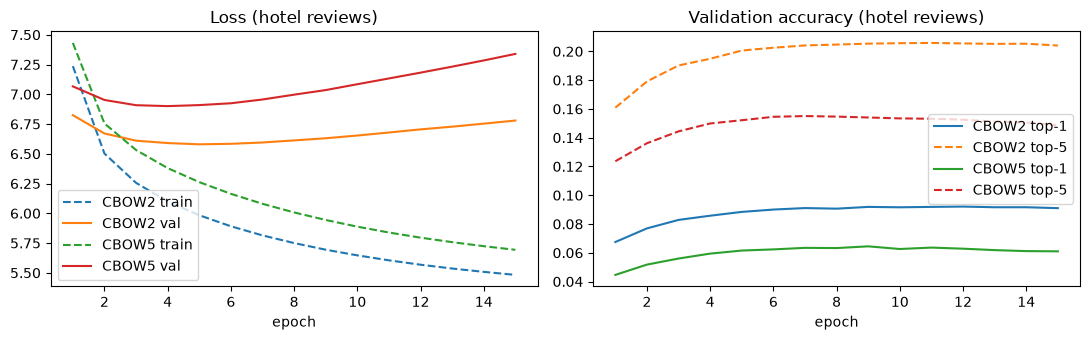

In [23]:
import matplotlib.pyplot as plt

rows = []
for name, history in [('CBOW2', history_hotel_cbow2), ('CBOW5', history_hotel_cbow5)]:
    last = history[-1]
    best = min(history, key=lambda r: r['val_loss'])
    rows.append({'model': name, 'train loss': last['train_loss'], 'val loss': last['val_loss'],
                 'val top-1': last['val_top1'], 'val top-5': last['val_top5'],
                 'best val loss': best['val_loss'], 'best epoch': best['epoch']})
display(pd.DataFrame(rows).set_index('model').round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, history in [('CBOW2', history_hotel_cbow2), ('CBOW5', history_hotel_cbow5)]:
    epochs = [r['epoch'] for r in history]
    axes[0].plot(epochs, [r['train_loss'] for r in history], '--', label=f'{name} train')
    axes[0].plot(epochs, [r['val_loss'] for r in history], label=f'{name} val')
    axes[1].plot(epochs, [r['val_top1'] for r in history], label=f'{name} top-1')
    axes[1].plot(epochs, [r['val_top5'] for r in history], '--', label=f'{name} top-5')
axes[0].set(title='Loss (hotel reviews)', xlabel='epoch')
axes[1].set(title='Validation accuracy (hotel reviews)', xlabel='epoch')
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

**Yes, the predictions are clearly sensitive to the context size.** Both models were trained on the same 9,000 reviews with identical settings and evaluated on the same 1,000 held-out reviews (103,684 target words):

| | val loss (epoch 15) | best val loss (epoch) | val top-1 | val top-5 |
|---|---|---|---|---|
| CBOW2 | 6.78 | 6.58 (5) | 9.1% | 20.4% |
| CBOW5 | 7.34 | 6.90 (4) | 6.1% | 14.9% |

- **CBOW2 is better at every point of training.** It predicts the missing word correctly 9.1% of the time, and has it among its top 5 guesses 20.4% of the time. CBOW5 manages 6.1% and 14.9%.
- **Why the wider window predicts worse.** CBOW *sums* the context vectors, so word order and distance are lost. With 5 words on each side, words that are far from the target, and only loosely related to it, get the same weight as its direct neighbours, so the signal is diluted. For predicting one specific word, the direct neighbours are the most informative context, especially in reviews without stopwords, where the words 4–5 positions away often belong to a different phrase.
- **CBOW5 also overfits more.**
  - Both models reach their lowest validation loss early (epoch 5 and epoch 4). After that the training loss keeps falling, but the validation loss rises: CBOW2 from 6.58 to 6.78, CBOW5 from 6.90 to 7.34.
  - A likely reason: with 10 context words, each training example is more specific, which makes it easier to memorise the training reviews. On a corpus of only ~1M tokens, 15 epochs are more than the prediction task needs.
- **Note on the embeddings.** The embeddings used in Parts 2 and 3 are taken after the final epoch (15 for hotel, 3 for Sci-Fi). The validation set is used to compare the models and to diagnose overfitting, not to select a checkpoint. Validation loss measures the word-prediction task, not the quality of the embeddings themselves. How the context size changes the *embeddings* is discussed in 2.5.

### 1.6 Train CBOW2 with a context width of 2 (in both directions) for the Sci-Fi story dataset

In [24]:
scifi_vocab = get_vocab(scifi_tokenized)
scifi_word2ix = get_word2ix(scifi_vocab, save_loc=os.path.join(SAVE_DIR, "scifi_word2ix.json"))
scifi_ix2word = {i: w for w, i in scifi_word2ix.items()}
print(f"Sci-Fi vocab: {len(scifi_vocab):,} (incl. <pad>, <unk>) instead of {len(get_vocab(scifi_tokenized, min_count=1)) - 2:,} without min_count")

model_scifi_cbow2, history_scifi_cbow2 = train_or_load('scifi_cbow2', scifi_tokenized, scifi_word2ix,
                                                      context_window=2, num_epochs=3)

Sci-Fi vocab: 46,026 (incl. <pad>, <unk>) instead of 114,635 without min_count
Loaded scifi_cbow2 from content/models/scifi_cbow2.pt (trained 3 epochs, final loss 5.7047, val loss 5.8377, val top-1 0.160, val top-5 0.323)


### Function for nearest neighbour computation

Complete the following function and use it to retrieve the closest words in Part 2. It should rank all words in the vocabulary by the cosine similarity of their embeddings to the embedding of the query word, the same measure that GloVe's `most_similar()` uses in Part 3. You may adapt the arguments to your model and vocabulary.

In [25]:
def get_closest_words(word, embedding, word_to_ix, ix_to_word, topn=5):
    """Return the topn words whose embeddings are most similar (cosine similarity) to the embedding of `word`.

    embedding:  the nn.Embedding layer of your trained model (e.g. model.embeddings)
    word_to_ix: dictionary from words to indices
    ix_to_word: dictionary (or list) from indices to words
    Returns a list of (word, similarity) pairs, most similar first, without the query word itself.
    """
    if word not in word_to_ix:
        return []

    weights = embedding.weight.detach()
    query_idx = word_to_ix[word]
    query_vec = weights[query_idx].unsqueeze(0)

    similarities = F.cosine_similarity(query_vec, weights, dim=1)
    top_scores, top_indices = torch.topk(similarities, k=topn + 3)  # +3: skip the query word, <pad> and <unk>

    results = []
    for idx, score in zip(top_indices.tolist(), top_scores.tolist()):
        if idx != query_idx and ix_to_word[idx] not in (PAD, UNK):
            results.append((ix_to_word[idx], score))
        if len(results) == topn:
            break
    return results

### 2.1 For the hotel reviews dataset, choose 3 nouns, 3 verbs, and 3 adjectives. (CBOW2 and optionally for CBOW5)
Make sure that some nouns/verbs/adjectives occur frequently in the corpus and that others are rare. For each of the 9 chosen words, retrieve the 5 closest words according to your trained CBOW2 model (you can use the function `get_closest_words` above).    

📝❓ List them in your report (at the end of this notebook) and comment on the performance of your model: do the neighbours the model provides make sense? Discuss.   


In [26]:
hotel_word_counts = Counter(w for s in hotel_tokenized for w in s)

# 3 nouns, 3 verbs, 3 adjectives (mix of frequent and rare words in the corpus)
hotel_words = {
    'Nouns': ['hotel', 'room', 'mattress'],         # frequent: hotel, room | rare: mattress
    'Verbs': ['stay', 'recommend', 'apologize'],    # frequent: stay, recommend | rare: apologize
    'Adjectives': ['great', 'clean', 'filthy'],     # frequent: great, clean | rare: filthy
}

def format_neighbors(neighbors):
    return ", ".join(f"{nw} ({sim:.3f})" for nw, sim in neighbors)

rows = []
for category, words in hotel_words.items():
    for w in words:
        rows.append({
            'Category': category,
            'Word': w,
            'Count': hotel_word_counts[w],
            'CBOW2 neighbours': format_neighbors(get_closest_words(w, model_hotel_cbow2.embeddings, hotel_word2ix, hotel_ix2word, topn=5)),
            'CBOW5 neighbours': format_neighbors(get_closest_words(w, model_hotel_cbow5.embeddings, hotel_word2ix, hotel_ix2word, topn=5)),
        })

hotel_neighbors_table = pd.DataFrame(rows).set_index(['Category', 'Word'])
with pd.option_context('display.max_colwidth', None):  # show the full neighbour lists
    display(hotel_neighbors_table)

Count  \
Category   Word               
Nouns      hotel      24531   
           room       17122   
           mattress     112   
Verbs      stay        7563   
           recommend   2398   
           apologize     15   
Adjectives great      10477   
           clean       4707   
           filthy        71   

                                                                                                   CBOW2 neighbours  \
Category   Word                                                                                                       
Nouns      hotel                     property (0.635), hotels (0.567), dylan (0.548), resort (0.548), place (0.517)   
           room                           rooms (0.818), rm (0.584), suite (0.528), citadines (0.512), ward (0.484)   
           mattress                  beds (0.686), mattresses (0.645), bed (0.561), blankets (0.528), duvet (0.525)   
Verbs      stay                     staying (0.621), return (0.615), visit (0.526), vacation (0.508), sleep (0.484)   
           recommend  recomend (0.797), recommended (0.792), reccomend (0.746), suggest (0.716), reccommend (0.679)   
           apologize       mosquito (0.554), wallet (0.526), apologizing (0.524), dedication (0.519), theft (0.509)   
Adjectives great              excellent (0.843), fantastic (0.811), good (0.798), superb (0.743), wonderful (0.729)   
           clean         spotless (0.787), immaculate (0.589), accessories (0.537), modernly (0.511), plump (0.495)   
           filthy                 dirty (0.768), shabby (0.627), threadbare (0.584), faintly (0.578), dated (0.520)   

                                                                                                   CBOW5 neighbours  
Category   Word                                                                                                      
Nouns      hotel               property (0.623), place (0.605), hotels (0.595), brilliantly (0.564), resort (0.527)  
           room                   rooms (0.838), webside (0.545), suite (0.512), shoulders (0.502), veranda (0.499)  
           mattress                   anyplace (0.581), beds (0.502), yet (0.502), degree (0.501), claiming (0.491)  
Verbs      stay               staying (0.656), return (0.648), visit (0.621), vacation (0.566), pretentious (0.532)  
           recommend  recommended (0.873), recomend (0.789), reccomend (0.767), suggest (0.742), reccommend (0.704)  
           apologize               spotted (0.563), smiles (0.502), commission (0.494), petra (0.489), kegs (0.489)  
Adjectives great              good (0.861), excellent (0.855), fantastic (0.803), perfect (0.768), fabulous (0.742)  
           clean                spotless (0.687), immaculate (0.585), suffering (0.563), airy (0.542), scan (0.529)  
           filthy                   dirty (0.733), switch (0.541), mildewy (0.540), santana (0.527), saliva (0.525)

| Category | Word (count) | CBOW2 neighbours |
|---|---|---|
| Noun | hotel (24,531) | property, hotels, dylan, resort, place |
| Noun | room (17,122) | rooms, rm, suite, citadines, ward |
| Noun | mattress (112) | beds, mattresses, bed, blankets, duvet |
| Verb | stay (7,563) | staying, return, visit, vacation, sleep |
| Verb | recommend (2,398) | recomend, recommended, reccomend, suggest, reccommend |
| Verb | apologize (15) | mosquito, wallet, apologizing, dedication, theft |
| Adjective | great (10,477) | excellent, fantastic, good, superb, wonderful |
| Adjective | clean (4,707) | spotless, immaculate, accessories, modernly, plump |
| Adjective | filthy (71) | dirty, shabby, threadbare, faintly, dated |

CBOW5 neighbours are in the table above and are discussed in 2.5.

**Do the neighbours make sense? Mostly yes.**
- **Frequent words get sensible neighbours.**
  - `great` → *excellent, fantastic, good, superb, wonderful* are near-synonyms.
  - `stay` → *staying, return, visit, vacation* are related travel verbs.
  - `hotel` → *property, resort, place* are what a reviewer would write instead of "hotel". Two neighbours are proper names that fill the same slot (*"stayed at the ___"*): *dylan* is presumably a hotel name, and *citadines* (under `room`) is an aparthotel chain.
- **Misspellings and inflections cluster with the correct word.** `recommend` → *recomend, reccomend, reccommend*; `room` → *rm*. The model never sees spelling; misspellings are close only because they occur in the same contexts. This shows that CBOW captures distributional, not orthographic, similarity.
- **Frequency matters, but distinctive contexts matter just as much.**
  - `mattress` (112) and `filthy` (71) are rare but get excellent neighbours (*beds, duvet, blankets*; *dirty, shabby, threadbare*). They occur in very consistent contexts (complaints about beds or about cleanliness).
  - `apologize` (15) is too rare. Apart from *apologizing*, its neighbours are noise, although *theft* and *wallet* hint at the incident reports in which apologies are mentioned.
  - The frequent `clean` has two perfect neighbours (*spotless, immaculate*) followed by noise (*accessories, modernly, plump*). It mostly appears in comma-separated lists of praise (*"clean, comfortable, spacious"*), so its context is generic.
- **Some neighbours are related but not synonyms.** `stay` → *sleep*, and `filthy` → *dated*. Distributional similarity mixes synonymy with relatedness.

### 2.2 Repeat 2.1 for SciFi Dataset

📝❓ List your findings for SciFi Dataset as well, similarly to 2.1

In [27]:
scifi_word_counts = Counter(w for s in scifi_tokenized for w in s)

# 3 nouns, 3 verbs, 3 adjectives (mix of frequent and rare words in the corpus)
scifi_words = {
    'Nouns': ['ship', 'planet', 'reactor'],            # frequent: ship, planet | rare: reactor
    'Verbs': ['said', 'looked', 'piloted'],            # frequent: said, looked | rare: piloted
    'Adjectives': ['human', 'alien', 'weightless'],    # frequent: human, alien | rare: weightless
}

rows = []
for category, words in scifi_words.items():
    for w in words:
        rows.append({
            'Category': category,
            'Word': w,
            'Count': scifi_word_counts[w],
            'CBOW2 neighbours': format_neighbors(get_closest_words(w, model_scifi_cbow2.embeddings, scifi_word2ix, scifi_ix2word, topn=5)),
        })

scifi_neighbors_table = pd.DataFrame(rows).set_index(['Category', 'Word'])
with pd.option_context('display.max_colwidth', None):  # show the full neighbour lists
    display(scifi_neighbors_table)

Count  \
Category   Word                
Nouns      ship         6242   
           planet       3377   
           reactor        54   
Verbs      said        30475   
           looked       7690   
           piloted        24   
Adjectives human        3812   
           alien        1484   
           weightless     52   

                                                                                                      CBOW2 neighbours  
Category   Word                                                                                                         
Nouns      ship                                car (0.816), craft (0.782), vessel (0.782), boat (0.781), fleet (0.756)  
           planet                           world (0.802), ship (0.707), species (0.701), island (0.695), race (0.685)  
           reactor             hardware (0.630), expansion (0.603), introductory (0.587), current (0.582), pad (0.562)  
Verbs      said               replied (0.862), murmured (0.843), answered (0.828), muttered (0.815), commented (0.808)  
           looked                       glanced (0.896), gazed (0.888), stared (0.871), glared (0.811), peered (0.800)  
           piloted                  followed (0.620), thrust (0.616), guided (0.596), hurled (0.583), operated (0.580)  
Adjectives human            sentient (0.684), intelligent (0.667), primitive (0.599), dominant (0.589), snotty (0.560)  
           alien                  reverend (0.643), enemy (0.641), animal (0.638), artificial (0.627), eyeport (0.613)  
           weightless  martian's (0.596), gravitators (0.572), landlord (0.561), crotch (0.551), uncomplicated (0.545)

| Category | Word (count) | CBOW2 neighbours |
|---|---|---|
| Noun | ship (6,242) | car, craft, vessel, boat, fleet |
| Noun | planet (3,377) | world, ship, species, island, race |
| Noun | reactor (54) | hardware, expansion, introductory, current, pad |
| Verb | said (30,475) | replied, murmured, answered, muttered, commented |
| Verb | looked (7,690) | glanced, gazed, stared, glared, peered |
| Verb | piloted (24) | followed, thrust, guided, hurled, operated |
| Adjective | human (3,812) | sentient, intelligent, primitive, dominant, snotty |
| Adjective | alien (1,484) | reverend, enemy, animal, artificial, eyeport |
| Adjective | weightless (52) | martian's, gravitators, landlord, crotch, uncomplicated |

**Discussion.**
- **The verbs are excellent.**
  - `said` → *replied, murmured, answered, muttered, commented* are all past-tense speech verbs (similarity 0.81–0.86).
  - `looked` → *glanced, gazed, stared, glared, peered* are all past-tense verbs of looking (0.80–0.90).
  - Even the rare `piloted` (24) gets past-tense verbs of controlling or moving something, *guided* and *operated* being the closest in meaning. The full syntax of the stories (*"he ___ the ship"*) constrains the slot strongly, so even few examples are enough.
- **Frequent nouns get co-hyponyms.**
  - `ship` → other vehicles (*craft, vessel, boat, car*) and *fleet*.
  - `planet` → *world, island*, but also *species, race*. These share contexts such as *"the human ___"* and *"the whole ___"*.
- **Adjectives depend on part-of-speech ambiguity.**
  - `human` → *sentient, intelligent, primitive, dominant* are properties of beings and races.
  - `alien` is both a noun and an adjective, and its neighbours mix the two: *enemy, animal* (noun sense), *artificial* (adjective sense), plus noise (*reverend, eyeport*).
- **Rare nouns and adjectives are mostly noise.**
  - `reactor` (54) has only loosely technical neighbours (*hardware, current*).
  - `weightless` (52) has one thematically related neighbour (*gravitators*) and otherwise noise.

### 2.3 📝❓ How does the quality of the hotel review-based embeddings compare with the Sci-fi-based embeddings? Elaborate.

**Overall, the Sci-Fi embeddings are of higher and more consistent quality.** The hotel embeddings capture domain-specific relations well, but they are noisier.

- **Frequent words.** Both models give good neighbours, but the Sci-Fi ones are tighter.
  - Sci-Fi similarities are 0.80–0.90: `said` → *replied, murmured, answered*; `looked` → *glanced, gazed, stared*.
  - Almost every Sci-Fi neighbour has the same part of speech and tense as the query word.
  - Hotel neighbours are mostly 0.5–0.8, and even frequent words have noise in positions 3–5 (`clean` → *accessories, modernly, plump*).
- **Rare words.** Neither corpus is reliable below about 50 occurrences, and the results vary:
  - Hotel: `mattress` (112) and `filthy` (71) are good, `apologize` (15) is noise.
  - Sci-Fi: `piloted` (24) is good, `reactor` (54) and `weightless` (52) are noise.
- **Prediction accuracy.** Validation top-1 accuracy is 16.0% for Sci-Fi and 9.1% for hotel CBOW2. The numbers are not strictly comparable, because the vocabularies differ and the Sci-Fi text contains easy-to-predict function words. They do agree with the qualitative picture.

Reasons:
1. **Amount of data.** Sci-Fi has about 7× more training pairs (6.47M vs 0.92M), so the average word is seen in many more contexts.
2. **Text quality.**
   - The hotel reviews have their stopwords removed, so a ±2 window often spans content words from different phrases (*"bathroom large sinks nice"*). It says little about the grammatical role of the target word.
   - The Sci-Fi text has full syntax (*"he ___ at the"*), which strongly constrains the part of speech. That is why its neighbours are so consistent.
   - The reviews also contain many misspellings and hotel names, which split counts and enter the neighbour lists (*recomend, dylan, citadines*).
3. **Training dynamics.**
   - The hotel models overfit: CBOW2's validation loss is lowest at epoch 5 (6.58) and rises to 6.78 by epoch 15, and we keep the epoch-15 embeddings.
   - The Sci-Fi model is, if anything, under-trained: its validation loss still falls after 3 epochs (6.03 → 5.89 → 5.84).

On the other hand, the hotel embeddings are exactly what a hotel-review application needs: *suite* for `room`, *duvet* and *blankets* for `mattress`, and *shabby* and *threadbare* for `filthy`.

### 2.4 Choose 2 words and retrieve their 5 closest neighbours according to hotel review-based embeddings and the Sci-fi-based embeddings.

📝❓ Do they have different neighbours? If yes, can you reason why?

In [28]:
shared_words = ['book', 'light']

for w in shared_words:
    hotel_nb = get_closest_words(w, model_hotel_cbow2.embeddings, hotel_word2ix, hotel_ix2word, topn=5)
    scifi_nb = get_closest_words(w, model_scifi_cbow2.embeddings, scifi_word2ix, scifi_ix2word, topn=5)
    print(f"Word: '{w}' (hotel count = {hotel_word_counts[w]}, scifi count = {scifi_word_counts[w]})")
    print("  Hotel CBOW2: ", ", ".join(f"{nw} ({sim:.3f})" for nw, sim in hotel_nb))
    print("  Sci-Fi CBOW2:", ", ".join(f"{nw} ({sim:.3f})" for nw, sim in scifi_nb))
    print()

Word: 'book' (hotel count = 827, scifi count = 1517)
  Hotel CBOW2:  booking (0.674), booked (0.632), reserve (0.617), cancel (0.554), reserved (0.536)
  Sci-Fi CBOW2: magazine (0.692), selection (0.688), story (0.663), books (0.626), encoded (0.614)

Word: 'light' (hotel count = 515, scifi count = 4465)
  Hotel CBOW2:  filters (0.553), desert (0.535), harrahs (0.534), flagged (0.509), clemens (0.494)
  Sci-Fi CBOW2: heat (0.708), sunlight (0.707), glow (0.680), lightning (0.664), sun (0.637)



| Word | Hotel CBOW2 (count) | Sci-Fi CBOW2 (count) |
|---|---|---|
| book | booking, booked, reserve, cancel, reserved (827) | magazine, selection, story, books, encoded (1,517) |
| light | filters, desert, harrahs, flagged, clemens (515) | heat, sunlight, glow, lightning, sun (4,465) |

**Yes, the neighbours are completely different, because the two corpora use the words in different senses, and for `book` even as different parts of speech.**
- **`book`.**
  - In the hotel reviews, `book` is almost always the *verb* (*"we booked the room"*, *"book directly with the hotel"*). Its neighbours are verbs and verb forms from the same reservation context: *booking, booked, reserve, reserved, cancel*.
  - In Sci-Fi, `book` is the *noun* (a book). Its neighbours are publications and texts: *magazine, story, books, selection*. This fits the corpus, which comes from Sci-Fi magazines that include editorial pages about stories and issues. *encoded* is less clear, perhaps from stories about information stored in books.
- **`light`.**
  - In Sci-Fi it is frequent (4,465) and means physical light: *sunlight, glow, lightning, sun, heat*. These are all words for light sources or radiation.
  - In the hotel reviews, `light` is rare (515) and has many senses: room lights, *light sleeper*, *light breakfast*, *light rail*, *natural light*. No sense dominates, so the vector is a noisy mixture and the neighbours are hard to interpret. *harrahs* (a Las Vegas casino) and *desert* may come from Las Vegas reviews; *filters* and *flagged* are noise.

**Reason.** CBOW learns one *static* vector per word from the contexts in *its own* corpus. Each vector encodes the sense (and part of speech) that dominates that corpus: *book* as a verb in reviews, as a noun in stories. When a word is rare and spread over several senses, as `light` is in the hotel reviews, the vector mixes them and its neighbours become noise. A contextual model (e.g. BERT) would instead give a different vector for each use of the word.

### 2.5 📝❓ What are the differences between CBOW2 and CBOW5 ? Can you "describe" them?    

**Prediction.** As shown in 1.5, CBOW2 predicts the missing word better than CBOW5 (validation top-1 9.1% vs 6.1%), and CBOW5 overfits more strongly. The wider window dilutes the signal, because CBOW sums all context words without any order or distance information.

**Embeddings.** The differences can be described as follows:
- **Words with a clear synonym set look similar in both models.** `great` → *excellent, fantastic, good*; `recommend` → *recommended, recomend, suggest*; `stay` → *staying, return, visit*. CBOW5 tends to give slightly higher similarities here, e.g. `great` → *good* 0.86 vs 0.80. The wide window captures the overall sentiment of a review, and positive adjectives occur in the same positive reviews.
- **CBOW2 captures functional (paradigmatic) similarity.** Its neighbours can *replace* the query in the same slot, with the same part of speech: `mattress` → *beds, mattresses, bed, blankets, duvet*; `filthy` → *dirty, shabby, threadbare*; `clean` → *spotless, immaculate*.
- **CBOW5 captures looser, topical associations.** Its neighbours are less consistent in part of speech: `room` → *veranda, shoulders, webside*; `clean` → *airy, suffering, scan*; `filthy` → *mildewy, saliva, switch*.
- **CBOW5 is much noisier for rare words.** `mattress` (112) → *anyplace, yet, degree, claiming* in CBOW5, but *beds, mattresses, bed* in CBOW2. Summing 10 context words averages away the few distinctive contexts a rare word has, and the stronger overfitting of CBOW5 adds noise.

**In short:** CBOW2 behaves like a "which word fits this slot?" model and gives syntactically and functionally similar neighbours. CBOW5 behaves more like a "which words appear in the same part of a review?" model and gives topically related, but less precise, neighbours.

### 3. Use the following code snippet to load a pretrained GloVe embedding model
GloVe (Global Vectors for Word Representation) (link to paper: https://aclanthology.org/D14-1162/) is a count-based model trained on very large text corpora. The vectors used here (glove.6B, 50 dimensions, the same size we recommend for your CBOW embeddings) were trained on Wikipedia and the Gigaword newswire corpus, about 6 billion tokens in total. Unlike CBOW, which learns to predict a target word from its local context, GloVe learns embeddings that capture global co-occurrence statistics of words across the entire corpus.

Each word in GloVe has one static vector, i.e. its embedding does not change depending on context.

Note: Only training needs a GPU. Once your models are trained and saved, you can do Parts 2 and 3 in a CPU runtime.

In [29]:
import numpy as np

In [30]:
import contextlib, io, os, sys, shutil
import gensim.downloader as api

# Clean up corrupted/incomplete gensim cache
glove_dir = os.path.join(api.BASE_DIR, "glove-wiki-gigaword-50")
if os.path.exists(glove_dir) and not os.path.exists(os.path.join(glove_dir, "__init__.py")):
    shutil.rmtree(glove_dir)
sys.modules.pop("glove-wiki-gigaword-50", None)

print("Loading GloVe (first run downloads ~66 MB, under a minute)...")
with contextlib.redirect_stdout(io.StringIO()):
    glove = api.load("glove-wiki-gigaword-50")
print(f"Loaded {len(glove.key_to_index):,} word vectors.")

Loading GloVe (first run downloads ~66 MB, under a minute)...
Loaded 400,000 word vectors.


In [31]:
### Insert your word selection from above here
trip_nouns = ['hotel', 'room', 'mattress']
trip_verbs = ['stay', 'recommend', 'apologize']
trip_adj = ['great', 'clean', 'filthy']


def glove_neighbors(w, topn=5):
    """Top-n GloVe neighbours (cosine similarity, via most_similar), formatted like the CBOW tables."""
    if w not in glove.key_to_index:
        return "(not in GloVe vocabulary)"
    return format_neighbors(glove.most_similar(w, topn=topn))


# Hotel words: CBOW2 and CBOW5 (hotel reviews) next to GloVe
rows = []
for category, words in [('Nouns', trip_nouns), ('Verbs', trip_verbs), ('Adjectives', trip_adj)]:
    for w in words:
        rows.append({
            'Category': category,
            'Word': w,
            'Count (hotel)': hotel_word_counts[w],
            'CBOW2 (hotel)': format_neighbors(get_closest_words(w, model_hotel_cbow2.embeddings, hotel_word2ix, hotel_ix2word, topn=5)),
            'CBOW5 (hotel)': format_neighbors(get_closest_words(w, model_hotel_cbow5.embeddings, hotel_word2ix, hotel_ix2word, topn=5)),
            'GloVe': glove_neighbors(w),
        })
hotel_glove_table = pd.DataFrame(rows).set_index(['Category', 'Word'])

# Sci-Fi words: CBOW2 (Sci-Fi) next to GloVe
rows = []
for category, words in scifi_words.items():
    for w in words:
        rows.append({
            'Category': category,
            'Word': w,
            'Count (Sci-Fi)': scifi_word_counts[w],
            'CBOW2 (Sci-Fi)': format_neighbors(get_closest_words(w, model_scifi_cbow2.embeddings, scifi_word2ix, scifi_ix2word, topn=5)),
            'GloVe': glove_neighbors(w),
        })
scifi_glove_table = pd.DataFrame(rows).set_index(['Category', 'Word'])

with pd.option_context('display.max_colwidth', None):  # show the full neighbour lists
    print("Hotel review words: CBOW vs. GloVe")
    display(hotel_glove_table)
    print("Sci-Fi words: CBOW vs. GloVe")
    display(scifi_glove_table)

Hotel review words: CBOW vs. GloVe


Count (hotel)  \
Category   Word                       
Nouns      hotel              24531   
           room               17122   
           mattress             112   
Verbs      stay                7563   
           recommend           2398   
           apologize             15   
Adjectives great              10477   
           clean               4707   
           filthy                71   

                                                                                                      CBOW2 (hotel)  \
Category   Word                                                                                                       
Nouns      hotel                     property (0.635), hotels (0.567), dylan (0.548), resort (0.548), place (0.517)   
           room                           rooms (0.818), rm (0.584), suite (0.528), citadines (0.512), ward (0.484)   
           mattress                  beds (0.686), mattresses (0.645), bed (0.561), blankets (0.528), duvet (0.525)   
Verbs      stay                     staying (0.621), return (0.615), visit (0.526), vacation (0.508), sleep (0.484)   
           recommend  recomend (0.797), recommended (0.792), reccomend (0.746), suggest (0.716), reccommend (0.679)   
           apologize       mosquito (0.554), wallet (0.526), apologizing (0.524), dedication (0.519), theft (0.509)   
Adjectives great              excellent (0.843), fantastic (0.811), good (0.798), superb (0.743), wonderful (0.729)   
           clean         spotless (0.787), immaculate (0.589), accessories (0.537), modernly (0.511), plump (0.495)   
           filthy                 dirty (0.768), shabby (0.627), threadbare (0.584), faintly (0.578), dated (0.520)   

                                                                                                      CBOW5 (hotel)  \
Category   Word                                                                                                       
Nouns      hotel               property (0.623), place (0.605), hotels (0.595), brilliantly (0.564), resort (0.527)   
           room                   rooms (0.838), webside (0.545), suite (0.512), shoulders (0.502), veranda (0.499)   
           mattress                   anyplace (0.581), beds (0.502), yet (0.502), degree (0.501), claiming (0.491)   
Verbs      stay               staying (0.656), return (0.648), visit (0.621), vacation (0.566), pretentious (0.532)   
           recommend  recommended (0.873), recomend (0.789), reccomend (0.767), suggest (0.742), reccommend (0.704)   
           apologize               spotted (0.563), smiles (0.502), commission (0.494), petra (0.489), kegs (0.489)   
Adjectives great              good (0.861), excellent (0.855), fantastic (0.803), perfect (0.768), fabulous (0.742)   
           clean                spotless (0.687), immaculate (0.585), suffering (0.563), airy (0.542), scan (0.529)   
           filthy                   dirty (0.733), switch (0.541), mildewy (0.540), santana (0.527), saliva (0.525)   

                                                                                                                           GloVe  
Category   Word                                                                                                                   
Nouns      hotel                               hotels (0.835), restaurant (0.801), inn (0.793), apartment (0.781), motel (0.779)  
           room                                      sitting (0.863), floor (0.846), door (0.846), rooms (0.843), filled (0.832)  
           mattress                      mattresses (0.783), cushions (0.758), pillow (0.747), cupboard (0.744), pillows (0.736)  
Verbs      stay                                      leave (0.935), wait (0.902), staying (0.895), take (0.867), waiting (0.865)  
           recommend  recommending (0.892), recommended (0.850), recommends (0.841), guidelines (0.805), recommendations (0.790)  
           apologize                   apologise (0.915

Sci-Fi words: CBOW vs. GloVe


Count (Sci-Fi)  \
Category   Word                         
Nouns      ship                  6242   
           planet                3377   
           reactor                 54   
Verbs      said                 30475   
           looked                7690   
           piloted                 24   
Adjectives human                 3812   
           alien                 1484   
           weightless              52   

                                                                                                        CBOW2 (Sci-Fi)  \
Category   Word                                                                                                          
Nouns      ship                                car (0.816), craft (0.782), vessel (0.782), boat (0.781), fleet (0.756)   
           planet                           world (0.802), ship (0.707), species (0.701), island (0.695), race (0.685)   
           reactor             hardware (0.630), expansion (0.603), introductory (0.587), current (0.582), pad (0.562)   
Verbs      said               replied (0.862), murmured (0.843), answered (0.828), muttered (0.815), commented (0.808)   
           looked                       glanced (0.896), gazed (0.888), stared (0.871), glared (0.811), peered (0.800)   
           piloted                  followed (0.620), thrust (0.616), guided (0.596), hurled (0.583), operated (0.580)   
Adjectives human            sentient (0.684), intelligent (0.667), primitive (0.599), dominant (0.589), snotty (0.560)   
           alien                  reverend (0.643), enemy (0.641), animal (0.638), artificial (0.627), eyeport (0.613)   
           weightless  martian's (0.596), gravitators (0.572), landlord (0.561), crotch (0.551), uncomplicated (0.545)   

                                                                                                                          GloVe  
Category   Word                                                                                                                  
Nouns      ship                                      vessel (0.936), ships (0.902), boat (0.890), aboard (0.842), cargo (0.826)  
           planet                              earth (0.876), planets (0.809), universe (0.800), mars (0.795), orbiting (0.752)  
           reactor                      reactors (0.900), yongbyon (0.826), plutonium (0.818), nuclear (0.805), uranium (0.785)  
Verbs      said                                    told (0.903), says (0.877), spokesman (0.850), saying (0.819), asked (0.817)  
           looked                                  seemed (0.886), looking (0.879), look (0.845), pretty (0.840), looks (0.840)  
           piloted                    unmanned (0.783), piloting (0.739), astronaut (0.729), aircraft (0.720), hijacked (0.703)  
Adjectives human                               animal (0.773), rights (0.764), aids (0.740), nature (0.737), particular (0.733)  
           alien                  aliens (0.854), creature (0.795), creatures (0.767), beings (0.741), extraterrestrial (0.730)  
           weightless  claustrophobic (0.698), accident-free (0.694), weightlessness (0.690), restful (0.686), bearable (0.684)

### 3.1 📝❓ Compare the GloVe neighbours with the ones you retrieved with your CBOW2 (and optionally CBOW5) models above. Do the GloVe neighbours seem more general or semantically broader? Are the CBOW neighbours more domain-specific to hotel reviews or the Sci-Fi text? Discuss how training data size and training objective (predictive vs. count-based) might explain the observed differences.

| Word | CBOW2 (own corpus) | GloVe |
|---|---|---|
| room | rooms, rm, suite, citadines, ward | sitting, floor, door, rooms, filled |
| stay | staying, return, visit, vacation, sleep | leave, wait, staying, take, waiting |
| great | excellent, fantastic, good, superb, wonderful | greatest, good, perhaps, life, well |
| clean | spotless, immaculate, accessories, modernly, plump | putting, enough, cleaning, water, needed |
| apologize (15) | mosquito, wallet, apologizing, dedication, theft | apologise, regret, apologized, regrets, regretted |
| said | replied, murmured, answered, muttered, commented | told, says, spokesman, saying, asked |
| planet | world, ship, species, island, race | earth, planets, universe, mars, orbiting |
| reactor (54) | hardware, expansion, introductory, current, pad | reactors, yongbyon, plutonium, nuclear, uranium |
| human | sentient, intelligent, primitive, dominant, snotty | animal, rights, aids, nature, particular |

**A. Comparison.**
- The two models agree only for a few words with one clear meaning: `mattress` → *mattresses / beds, pillow / blankets*, and `ship` → *vessel, boat* in both.
- For most words the neighbours are very different. GloVe similarities are also much higher (0.7–0.94, vs 0.5–0.9 for CBOW).

**B. Are the GloVe neighbours more general or semantically broader? Yes.** They reflect the language of Wikipedia and newswire, not of hotel reviews or stories.
- **General or news senses instead of the domain sense.**
  - `room` → *sitting, floor, door* (a room in any building, as in *sitting room*), not a hotel room.
  - `stay` → *leave, wait* ("stay/remain"), not "stay at a hotel".
  - `great` → *greatest, perhaps, life* (*great deal*, *the greatest*), not praise.
  - `clean` → *water, cleaning, putting* (the verb, and *clean water*), not a spotless room.
  - `recommend` → *guidelines, recommendations* (official recommendations).
- **News topics.**
  - `said` → *spokesman, told, says* (reporting language).
  - `human` → *rights, aids* (*human rights*, *HIV/AIDS*).
  - `reactor` → *yongbyon, plutonium, uranium* (news about North Korea's nuclear programme).
  - `filthy` → *lucre* (the idiom *filthy lucre*).
- **More morphological variants and topical associates.**
  - Variants: *recommending, recommends*; *ships*; *planets*; *reactors*; *aliens*.
  - Topically related words that can't replace the query in a sentence: *aboard, cargo* for `ship`, *orbiting* for `planet`, *astronaut, aircraft* for `piloted`.

**C. Are the CBOW neighbours more domain-specific? Yes, clearly.**
- **Hotel CBOW** gives the reviewers' vocabulary:
  - *suite* for `room`, and *vacation, visit* for `stay`
  - *spotless, immaculate* for `clean`, and *excellent, superb* for `great` (evaluative language)
  - hotel names (*dylan, citadines*) and common misspellings (*recomend*)
- **Sci-Fi CBOW** gives the language of narrative fiction:
  - `said` → *murmured, muttered, replied* (dialogue verbs, not reporting verbs)
  - `looked` → *glanced, gazed, stared* (GloVe: *seemed, looks*)
  - `ship` → *craft, fleet* (spacecraft rather than GloVe's maritime *cargo*)
  - `human` → *sentient, intelligent* (humans as one species among others)
- **One instructive exception: `alien`.** Here GloVe (*aliens, creature, extraterrestrial*) is more "Sci-Fi" than our Sci-Fi model, whose neighbours are noisy. In the stories `alien` is used both as a noun and as an adjective, and the CBOW vector mixes the two uses.

**D. How training data size and training objective explain the differences.**
- **Data size.**
  - GloVe was trained on ~6 billion tokens; our corpora have ~1M (hotel) and ~7.3M (Sci-Fi) tokens.
  - That is why GloVe is far better for rare words. `apologize` (15 occurrences in the reviews), `reactor` (54), `piloted` (24) and `weightless` (52) are mostly noise in CBOW but sensible in GloVe (*apologise, regret*; *reactors, nuclear*; *piloting, aircraft*; *weightlessness*).
  - At the same time, in a large general corpus the most frequent, general sense of a word dominates its vector. The hotel or Sci-Fi sense is drowned out. A small domain corpus does the opposite: it sees only the domain sense, which makes CBOW more domain-specific but also noisier.
- **Training objective.**
  - CBOW is *predictive*. With a ±2 window it learns which words fit the same *slot* in a sentence, so its neighbours are mostly substitutes of the same part of speech and form (`said` → *replied, murmured*).
  - GloVe is *count-based*. It fits word vectors to the log of a *global* co-occurrence matrix, built with a wider window (10 words on each side in the original paper). Two words are similar if they co-occur with the same words *anywhere in the corpus*. This captures broader topical association and morphology (`planet` → *orbiting*, `reactor` → *plutonium*).
  - Part of this difference comes from window size and corpus rather than from the objective itself. Levy & Goldberg (2014) showed that predictive and count-based embeddings are closely related, since both implicitly factorise a word–context association matrix.

---

## Lab report

This report collects the answers to all questions marked with 📝❓. The same answers also appear directly below each question in the notebook, next to the code and outputs they refer to.

### Questions

**1.3 Preprocessing**

- 📝❓ Describe your decisions for preprocessing the datasets and for the structure of your classes.

*Summary of the preprocessing steps:*

| # | Step | Hotel reviews | Sci-Fi stories | Why |
|---|---|---|---|---|
| 1 | **Load** | `Review` column of the CSV, empty rows dropped (10,000 reviews) | whole file as one string (43M characters, no line breaks) | |
| 2 | **Split into sequences** | one sequence per review | split into sentences at `.`, `!`, `?` | Reviews have no reliable sentence boundaries. Context windows never cross a sequence boundary |
| 3 | **Lowercase** | yes (already lowercase) | yes | `The` and `the` should share one embedding |
| 4 | **Tokenise** | regex `[a-z]+(?:'[a-z]+)*` → 1,053,491 tokens, 34,648 distinct tokens | same → 7,271,935 tokens, 114,635 distinct tokens (512,946 sentences) | Keeps contractions as one token (`n't`, `don't`, `it's`). The old `[a-z]+` split them into `n` + `t` / `don` + `t`. Drops punctuation and numbers, and splits glued words such as `world.the`. Curly apostrophes (’) are normalised to `'` first |
| 5 | **Drop short sequences** | sequences < 5 tokens (none dropped) | sentences < 5 tokens | Very short fragments (headers, OCR debris) carry little context |
| 6 | **Stopwords** | kept (most were already removed in this dataset) | kept | CBOW learns from local context; function words such as `not` and `was` carry syntactic information |
| 7 | **Vocabulary with `min_count = 3`** | 34,648 distinct tokens → 13,814 kept → vocab size 13,816 incl. `<pad>`, `<unk>` | 114,635 distinct tokens → 46,024 kept → vocab size 46,026 | Words seen fewer than 3 times (≈60% of distinct tokens, but only 2.4% / 1.1% of all tokens) are mostly typos and OCR errors. They get no useful embedding and would show up as nonsense neighbours. They are mapped to `<unk>`, which also shrinks the output layer about 2.5× |
| 8 | **Context-target pairs with padding** | every known word is a target: 1,028,354 pairs (CBOW2 and CBOW5) | 7,191,503 pairs | Each sequence is padded with `context_window` × `<pad>` on both sides, so words at sequence edges are targets too. `<pad>` has a fixed zero embedding (`padding_idx`). `<unk>` may appear in a context but is never a target |
| 9 | **Train / validation split** | 10% of the reviews held out (1,000 reviews) | 10% of the sentences held out (51,294 sentences) | Split by sequence, so overlapping windows never end up in both sets. Used to compare CBOW2 and CBOW5 on unseen text (validation loss, top-1/top-5 accuracy) and to detect overfitting. The vocabulary is built on the full corpus |

The table lists every preprocessing step with its effect on the data. These are the main decisions and the reasons behind them:

- **One sequence per review, one sequence per sentence.**
  - The hotel reviews have no reliable sentence boundaries: commas and full stops are used loosely, and full stops are often not followed by a space (`world.the`). We therefore treat each review as one sequence.
  - The Sci-Fi file is one 43M-character line, so we split it into sentences at `.`, `!` and `?`.
  - Context windows never cross a sequence boundary.
- **Lowercasing and a regex tokeniser.**
  - We lowercase everything and keep alphabetic words, with internal apostrophes allowed (`[a-z]+(?:'[a-z]+)*`).
  - Keeping apostrophes matters: a plain `[a-z]+` splits `n't` into `n` + `t`. The hotel data has about 9,300 such negations, so negation, which is important for reviews, would become meaningless tokens.
  - Punctuation and numbers are dropped, because they are sparse and carry little lexical meaning here.
- **Sentences shorter than 5 tokens are dropped.** In Sci-Fi these are mostly magazine headers and OCR debris. No hotel review is that short.
- **Stopwords are kept.**
  - CBOW learns from local context, and function words carry syntactic information. Removing them would also put words next to each other that were not adjacent in the text.
  - The hotel reviews already have most stopwords removed, apart from `not`, `did` and a few others.
- **Minimum count of 3; rarer words become `<unk>`.**
  - About 60% of the distinct tokens occur only once or twice. They are mostly typos and glued words (`patissserie`, `orleansthe`) and OCR errors, and they cover only 2.4% (hotel) and 1.1% (Sci-Fi) of all tokens.
  - These words cannot get a meaningful embedding, and without the filter they appeared as nonsense neighbours.
  - The filter also makes the output layer about 2.5× smaller, which speeds up training.
  - `<unk>` may appear as a context word but is never a prediction target.
- **Padding instead of skipping edge words.**
  - Each sequence is padded with `<pad>` tokens, so the first and last words of a sentence are also training targets. Without padding, Sci-Fi would lose about 2 million targets, 4 per sentence.
  - `<pad>` is the `padding_idx` of the embedding layer, so its vector is fixed at zero and adds nothing to the summed context.
- **Train/validation split by sequence (10%).**
  - This lets us compare CBOW2 and CBOW5 on unseen text and detect overfitting.
  - We split by whole review or sentence rather than by individual pairs, because neighbouring context windows overlap.
  - The vocabulary is built on the full corpus.

**Class and function structure.**
- `custom_preprocess` handles sequence splitting, tokenisation and the length filter.
- `get_vocab` and `get_word2ix` build the vocabulary (`<pad>`, `<unk>` and then the sorted words, so indices are reproducible) and save it as JSON.
- `get_data` builds the padded `(context_words, target)` pairs. `make_tensors` and `make_loader` turn them into index tensors and shuffled mini-batches.
- `CBOW(nn.Module)` consists of an `nn.Embedding(|V|, 50)`, which holds the word vectors, and an `nn.Linear(50, |V|)`. `forward` sums the context embeddings and returns scores over the vocabulary. `nn.CrossEntropyLoss` applies the softmax, so training minimises −log softmax(A·Σq_w + b), as in the CBOW definition.
- `train` uses Adam (lr 0.003) and cross-entropy loss with batch size 512. After every epoch, `evaluate` reports the validation loss and top-1/top-5 accuracy.
- `train_or_load` performs the split, then trains and saves a model, or reloads it from disk so Parts 2 and 3 can be re-run without a GPU.
- Training settings: embedding size 50, 15 epochs for hotel and 3 for Sci-Fi, a fixed seed per model. The embeddings are taken after the final epoch.

**1.5 CBOW5**

- 📝❓ Are predictions made by the model sensitive towards the context size?

**Yes, the predictions are clearly sensitive to the context size.** Both models were trained on the same 9,000 reviews with identical settings and evaluated on the same 1,000 held-out reviews (103,684 target words):

| | val loss (epoch 15) | best val loss (epoch) | val top-1 | val top-5 |
|---|---|---|---|---|
| CBOW2 | 6.78 | 6.58 (5) | 9.1% | 20.4% |
| CBOW5 | 7.34 | 6.90 (4) | 6.1% | 14.9% |

- **CBOW2 is better at every point of training.** It predicts the missing word correctly 9.1% of the time, and has it among its top 5 guesses 20.4% of the time. CBOW5 manages 6.1% and 14.9%.
- **Why the wider window predicts worse.** CBOW *sums* the context vectors, so word order and distance are lost. With 5 words on each side, words that are far from the target, and only loosely related to it, get the same weight as its direct neighbours, so the signal is diluted. For predicting one specific word, the direct neighbours are the most informative context, especially in reviews without stopwords, where the words 4–5 positions away often belong to a different phrase.
- **CBOW5 also overfits more.**
  - Both models reach their lowest validation loss early (epoch 5 and epoch 4). After that the training loss keeps falling, but the validation loss rises: CBOW2 from 6.58 to 6.78, CBOW5 from 6.90 to 7.34.
  - A likely reason: with 10 context words, each training example is more specific, which makes it easier to memorise the training reviews. On a corpus of only ~1M tokens, 15 epochs are more than the prediction task needs.
- **Note on the embeddings.** The embeddings used in Parts 2 and 3 are taken after the final epoch (15 for hotel, 3 for Sci-Fi). The validation set is used to compare the models and to diagnose overfitting, not to select a checkpoint. Validation loss measures the word-prediction task, not the quality of the embeddings themselves. How the context size changes the *embeddings* is discussed in 2.5.

**2.1 Hotel reviews**

- 📝❓ List the 5 closest words for each of your 9 chosen words and comment on the performance of your model: do the neighbours the model provides make sense? Discuss.

| Category | Word (count) | CBOW2 neighbours |
|---|---|---|
| Noun | hotel (24,531) | property, hotels, dylan, resort, place |
| Noun | room (17,122) | rooms, rm, suite, citadines, ward |
| Noun | mattress (112) | beds, mattresses, bed, blankets, duvet |
| Verb | stay (7,563) | staying, return, visit, vacation, sleep |
| Verb | recommend (2,398) | recomend, recommended, reccomend, suggest, reccommend |
| Verb | apologize (15) | mosquito, wallet, apologizing, dedication, theft |
| Adjective | great (10,477) | excellent, fantastic, good, superb, wonderful |
| Adjective | clean (4,707) | spotless, immaculate, accessories, modernly, plump |
| Adjective | filthy (71) | dirty, shabby, threadbare, faintly, dated |

CBOW5 neighbours are listed in the table in section 2.1 and are discussed in 2.5.

**Do the neighbours make sense? Mostly yes.**
- **Frequent words get sensible neighbours.**
  - `great` → *excellent, fantastic, good, superb, wonderful* are near-synonyms.
  - `stay` → *staying, return, visit, vacation* are related travel verbs.
  - `hotel` → *property, resort, place* are what a reviewer would write instead of "hotel". Two neighbours are proper names that fill the same slot (*"stayed at the ___"*): *dylan* is presumably a hotel name, and *citadines* (under `room`) is an aparthotel chain.
- **Misspellings and inflections cluster with the correct word.** `recommend` → *recomend, reccomend, reccommend*; `room` → *rm*. The model never sees spelling; misspellings are close only because they occur in the same contexts. This shows that CBOW captures distributional, not orthographic, similarity.
- **Frequency matters, but distinctive contexts matter just as much.**
  - `mattress` (112) and `filthy` (71) are rare but get excellent neighbours (*beds, duvet, blankets*; *dirty, shabby, threadbare*). They occur in very consistent contexts (complaints about beds or about cleanliness).
  - `apologize` (15) is too rare. Apart from *apologizing*, its neighbours are noise, although *theft* and *wallet* hint at the incident reports in which apologies are mentioned.
  - The frequent `clean` has two perfect neighbours (*spotless, immaculate*) followed by noise (*accessories, modernly, plump*). It mostly appears in comma-separated lists of praise (*"clean, comfortable, spacious"*), so its context is generic.
- **Some neighbours are related but not synonyms.** `stay` → *sleep*, and `filthy` → *dated*. Distributional similarity mixes synonymy with relatedness.

**2.2 Sci-Fi stories**

- 📝❓ List your findings for the Sci-Fi dataset as well, similarly to 2.1.

| Category | Word (count) | CBOW2 neighbours |
|---|---|---|
| Noun | ship (6,242) | car, craft, vessel, boat, fleet |
| Noun | planet (3,377) | world, ship, species, island, race |
| Noun | reactor (54) | hardware, expansion, introductory, current, pad |
| Verb | said (30,475) | replied, murmured, answered, muttered, commented |
| Verb | looked (7,690) | glanced, gazed, stared, glared, peered |
| Verb | piloted (24) | followed, thrust, guided, hurled, operated |
| Adjective | human (3,812) | sentient, intelligent, primitive, dominant, snotty |
| Adjective | alien (1,484) | reverend, enemy, animal, artificial, eyeport |
| Adjective | weightless (52) | martian's, gravitators, landlord, crotch, uncomplicated |

**Discussion.**
- **The verbs are excellent.**
  - `said` → *replied, murmured, answered, muttered, commented* are all past-tense speech verbs (similarity 0.81–0.86).
  - `looked` → *glanced, gazed, stared, glared, peered* are all past-tense verbs of looking (0.80–0.90).
  - Even the rare `piloted` (24) gets past-tense verbs of controlling or moving something, *guided* and *operated* being the closest in meaning. The full syntax of the stories (*"he ___ the ship"*) constrains the slot strongly, so even few examples are enough.
- **Frequent nouns get co-hyponyms.**
  - `ship` → other vehicles (*craft, vessel, boat, car*) and *fleet*.
  - `planet` → *world, island*, but also *species, race*. These share contexts such as *"the human ___"* and *"the whole ___"*.
- **Adjectives depend on part-of-speech ambiguity.**
  - `human` → *sentient, intelligent, primitive, dominant* are properties of beings and races.
  - `alien` is both a noun and an adjective, and its neighbours mix the two: *enemy, animal* (noun sense), *artificial* (adjective sense), plus noise (*reverend, eyeport*).
- **Rare nouns and adjectives are mostly noise.**
  - `reactor` (54) has only loosely technical neighbours (*hardware, current*).
  - `weightless` (52) has one thematically related neighbour (*gravitators*) and otherwise noise.

**2.3 Comparing the two datasets**

- 📝❓ How does the quality of the hotel review-based embeddings compare with the Sci-fi-based embeddings? Elaborate.

**Overall, the Sci-Fi embeddings are of higher and more consistent quality.** The hotel embeddings capture domain-specific relations well, but they are noisier.

- **Frequent words.** Both models give good neighbours, but the Sci-Fi ones are tighter.
  - Sci-Fi similarities are 0.80–0.90: `said` → *replied, murmured, answered*; `looked` → *glanced, gazed, stared*.
  - Almost every Sci-Fi neighbour has the same part of speech and tense as the query word.
  - Hotel neighbours are mostly 0.5–0.8, and even frequent words have noise in positions 3–5 (`clean` → *accessories, modernly, plump*).
- **Rare words.** Neither corpus is reliable below about 50 occurrences, and the results vary:
  - Hotel: `mattress` (112) and `filthy` (71) are good, `apologize` (15) is noise.
  - Sci-Fi: `piloted` (24) is good, `reactor` (54) and `weightless` (52) are noise.
- **Prediction accuracy.** Validation top-1 accuracy is 16.0% for Sci-Fi and 9.1% for hotel CBOW2. The numbers are not strictly comparable, because the vocabularies differ and the Sci-Fi text contains easy-to-predict function words. They do agree with the qualitative picture.

Reasons:
1. **Amount of data.** Sci-Fi has about 7× more training pairs (6.47M vs 0.92M), so the average word is seen in many more contexts.
2. **Text quality.**
   - The hotel reviews have their stopwords removed, so a ±2 window often spans content words from different phrases (*"bathroom large sinks nice"*). It says little about the grammatical role of the target word.
   - The Sci-Fi text has full syntax (*"he ___ at the"*), which strongly constrains the part of speech. That is why its neighbours are so consistent.
   - The reviews also contain many misspellings and hotel names, which split counts and enter the neighbour lists (*recomend, dylan, citadines*).
3. **Training dynamics.**
   - The hotel models overfit: CBOW2's validation loss is lowest at epoch 5 (6.58) and rises to 6.78 by epoch 15, and we keep the epoch-15 embeddings.
   - The Sci-Fi model is, if anything, under-trained: its validation loss still falls after 3 epochs (6.03 → 5.89 → 5.84).

On the other hand, the hotel embeddings are exactly what a hotel-review application needs: *suite* for `room`, *duvet* and *blankets* for `mattress`, and *shabby* and *threadbare* for `filthy`.

**2.4 Same words, different neighbours**

- 📝❓ Do your 2 chosen words have different neighbours in the hotel review-based and the Sci-fi-based embeddings? If yes, can you reason why?

| Word | Hotel CBOW2 (count) | Sci-Fi CBOW2 (count) |
|---|---|---|
| book | booking, booked, reserve, cancel, reserved (827) | magazine, selection, story, books, encoded (1,517) |
| light | filters, desert, harrahs, flagged, clemens (515) | heat, sunlight, glow, lightning, sun (4,465) |

**Yes, the neighbours are completely different, because the two corpora use the words in different senses, and for `book` even as different parts of speech.**
- **`book`.**
  - In the hotel reviews, `book` is almost always the *verb* (*"we booked the room"*, *"book directly with the hotel"*). Its neighbours are verbs and verb forms from the same reservation context: *booking, booked, reserve, reserved, cancel*.
  - In Sci-Fi, `book` is the *noun* (a book). Its neighbours are publications and texts: *magazine, story, books, selection*. This fits the corpus, which comes from Sci-Fi magazines that include editorial pages about stories and issues. *encoded* is less clear, perhaps from stories about information stored in books.
- **`light`.**
  - In Sci-Fi it is frequent (4,465) and means physical light: *sunlight, glow, lightning, sun, heat*. These are all words for light sources or radiation.
  - In the hotel reviews, `light` is rare (515) and has many senses: room lights, *light sleeper*, *light breakfast*, *light rail*, *natural light*. No sense dominates, so the vector is a noisy mixture and the neighbours are hard to interpret. *harrahs* (a Las Vegas casino) and *desert* may come from Las Vegas reviews; *filters* and *flagged* are noise.

**Reason.** CBOW learns one *static* vector per word from the contexts in *its own* corpus. Each vector encodes the sense (and part of speech) that dominates that corpus: *book* as a verb in reviews, as a noun in stories. When a word is rare and spread over several senses, as `light` is in the hotel reviews, the vector mixes them and its neighbours become noise. A contextual model (e.g. BERT) would instead give a different vector for each use of the word.

**2.5 CBOW2 vs. CBOW5**

- 📝❓ What are the differences between CBOW2 and CBOW5? Can you "describe" them?

**Prediction.** As shown in 1.5, CBOW2 predicts the missing word better than CBOW5 (validation top-1 9.1% vs 6.1%), and CBOW5 overfits more strongly. The wider window dilutes the signal, because CBOW sums all context words without any order or distance information.

**Embeddings.** The differences can be described as follows:
- **Words with a clear synonym set look similar in both models.** `great` → *excellent, fantastic, good*; `recommend` → *recommended, recomend, suggest*; `stay` → *staying, return, visit*. CBOW5 tends to give slightly higher similarities here, e.g. `great` → *good* 0.86 vs 0.80. The wide window captures the overall sentiment of a review, and positive adjectives occur in the same positive reviews.
- **CBOW2 captures functional (paradigmatic) similarity.** Its neighbours can *replace* the query in the same slot, with the same part of speech: `mattress` → *beds, mattresses, bed, blankets, duvet*; `filthy` → *dirty, shabby, threadbare*; `clean` → *spotless, immaculate*.
- **CBOW5 captures looser, topical associations.** Its neighbours are less consistent in part of speech: `room` → *veranda, shoulders, webside*; `clean` → *airy, suffering, scan*; `filthy` → *mildewy, saliva, switch*.
- **CBOW5 is much noisier for rare words.** `mattress` (112) → *anyplace, yet, degree, claiming* in CBOW5, but *beds, mattresses, bed* in CBOW2. Summing 10 context words averages away the few distinctive contexts a rare word has, and the stronger overfitting of CBOW5 adds noise.

**In short:** CBOW2 behaves like a "which word fits this slot?" model and gives syntactically and functionally similar neighbours. CBOW5 behaves more like a "which words appear in the same part of a review?" model and gives topically related, but less precise, neighbours.

**3.1 Comparison with GloVe**

- 📝❓ Do the GloVe neighbours seem more general or semantically broader? Are the CBOW neighbours more domain-specific to hotel reviews or the Sci-Fi text? Discuss how training data size and training objective (predictive vs. count-based) might explain the observed differences.

The full side-by-side tables are in section 3. Selected examples:

| Word | CBOW2 (own corpus) | GloVe |
|---|---|---|
| room | rooms, rm, suite, citadines, ward | sitting, floor, door, rooms, filled |
| stay | staying, return, visit, vacation, sleep | leave, wait, staying, take, waiting |
| great | excellent, fantastic, good, superb, wonderful | greatest, good, perhaps, life, well |
| clean | spotless, immaculate, accessories, modernly, plump | putting, enough, cleaning, water, needed |
| apologize (15) | mosquito, wallet, apologizing, dedication, theft | apologise, regret, apologized, regrets, regretted |
| said | replied, murmured, answered, muttered, commented | told, says, spokesman, saying, asked |
| planet | world, ship, species, island, race | earth, planets, universe, mars, orbiting |
| reactor (54) | hardware, expansion, introductory, current, pad | reactors, yongbyon, plutonium, nuclear, uranium |
| human | sentient, intelligent, primitive, dominant, snotty | animal, rights, aids, nature, particular |

**A. Comparison.**
- The two models agree only for a few words with one clear meaning: `mattress` → *mattresses / beds, pillow / blankets*, and `ship` → *vessel, boat* in both.
- For most words the neighbours are very different. GloVe similarities are also much higher (0.7–0.94, vs 0.5–0.9 for CBOW).

**B. Are the GloVe neighbours more general or semantically broader? Yes.** They reflect the language of Wikipedia and newswire, not of hotel reviews or stories.
- **General or news senses instead of the domain sense.**
  - `room` → *sitting, floor, door* (a room in any building, as in *sitting room*), not a hotel room.
  - `stay` → *leave, wait* ("stay/remain"), not "stay at a hotel".
  - `great` → *greatest, perhaps, life* (*great deal*, *the greatest*), not praise.
  - `clean` → *water, cleaning, putting* (the verb, and *clean water*), not a spotless room.
  - `recommend` → *guidelines, recommendations* (official recommendations).
- **News topics.**
  - `said` → *spokesman, told, says* (reporting language).
  - `human` → *rights, aids* (*human rights*, *HIV/AIDS*).
  - `reactor` → *yongbyon, plutonium, uranium* (news about North Korea's nuclear programme).
  - `filthy` → *lucre* (the idiom *filthy lucre*).
- **More morphological variants and topical associates.**
  - Variants: *recommending, recommends*; *ships*; *planets*; *reactors*; *aliens*.
  - Topically related words that can't replace the query in a sentence: *aboard, cargo* for `ship`, *orbiting* for `planet`, *astronaut, aircraft* for `piloted`.

**C. Are the CBOW neighbours more domain-specific? Yes, clearly.**
- **Hotel CBOW** gives the reviewers' vocabulary:
  - *suite* for `room`, and *vacation, visit* for `stay`
  - *spotless, immaculate* for `clean`, and *excellent, superb* for `great` (evaluative language)
  - hotel names (*dylan, citadines*) and common misspellings (*recomend*)
- **Sci-Fi CBOW** gives the language of narrative fiction:
  - `said` → *murmured, muttered, replied* (dialogue verbs, not reporting verbs)
  - `looked` → *glanced, gazed, stared* (GloVe: *seemed, looks*)
  - `ship` → *craft, fleet* (spacecraft rather than GloVe's maritime *cargo*)
  - `human` → *sentient, intelligent* (humans as one species among others)
- **One instructive exception: `alien`.** Here GloVe (*aliens, creature, extraterrestrial*) is more "Sci-Fi" than our Sci-Fi model, whose neighbours are noisy. In the stories `alien` is used both as a noun and as an adjective, and the CBOW vector mixes the two uses.

**D. How training data size and training objective explain the differences.**
- **Data size.**
  - GloVe was trained on ~6 billion tokens; our corpora have ~1M (hotel) and ~7.3M (Sci-Fi) tokens.
  - That is why GloVe is far better for rare words. `apologize` (15 occurrences in the reviews), `reactor` (54), `piloted` (24) and `weightless` (52) are mostly noise in CBOW but sensible in GloVe (*apologise, regret*; *reactors, nuclear*; *piloting, aircraft*; *weightlessness*).
  - At the same time, in a large general corpus the most frequent, general sense of a word dominates its vector. The hotel or Sci-Fi sense is drowned out. A small domain corpus does the opposite: it sees only the domain sense, which makes CBOW more domain-specific but also noisier.
- **Training objective.**
  - CBOW is *predictive*. With a ±2 window it learns which words fit the same *slot* in a sentence, so its neighbours are mostly substitutes of the same part of speech and form (`said` → *replied, murmured*).
  - GloVe is *count-based*. It fits word vectors to the log of a *global* co-occurrence matrix, built with a wider window (10 words on each side in the original paper). Two words are similar if they co-occur with the same words *anywhere in the corpus*. This captures broader topical association and morphology (`planet` → *orbiting*, `reactor` → *plutonium*).
  - Part of this difference comes from window size and corpus rather than from the objective itself. Levy & Goldberg (2014) showed that predictive and count-based embeddings are closely related, since both implicitly factorise a word–context association matrix.

## Declarations

Please fill in both declarations below by editing this cell (double-click it). Mark the applicable option by replacing ☐ with ☒ (copy the symbol from here: ☒) and complete the text field where required. Your reviewers will check that both declarations are present and completed.

### Contribution declaration

By submitting this work, the group declares that the contributions of the group members were:

☒ approximately equal

☐ not approximately equal

If the contributions were not approximately equal, no individual group member needs to be identified.

### Declaration on the use of AI

The group declares that any use of AI-based tools in preparing this work complied with the rules specified for this exercise.

☐ No AI-based tools were used.

☒ AI-based tools were used in accordance with the rules of the exercise.

If AI-based tools were used, briefly state the tool(s) used and the purpose(s) for which they were used:

**Tool:** Claude (Anthropic), used through Claude Code.

**Purposes:**
- *Code:* explaining and debugging code. Suggesting and implementing improvements, saving and loading trained models.
- *Analysis and report:* comparing alternative approaches. Drafting the markdown answers from our executed outputs.

We reviewed, tested and edited all AI-assisted code and text, checked the reported numbers against our own outputs, and can explain every part of the submission.